# hebron_change_detection_v3
**Optical team · 856.114 GeoHumanitarian Action · Z_GIS–MSF West Bank hackathon**
Sentinel-2 (10 m) · Google Earth Engine in Colab · **2020–2026** · two images per year (spring + summer)

| Part | Question | What you get |
|---|---|---|
| **1 – Buildings change** | Where and when did built-up areas grow? What disappeared? How different are we from existing products? | Land cover per year, year each new built-up area appeared (red), bare → built, built-up that disappeared, comparison with existing products, reported places, charts, GIFs, maps |
| **2 – Damage from reports** | Can reported demolitions or land clearing be seen? | Per incident: site-vs-surroundings test, local change map, single-day strip, plain verdict. Incidents by name, coordinates, drawing or **KMZ / KML / GeoJSON upload** |
| **3 – Focus areas and downloads** | Hand-over | Statistics and maps per MSF focus area (upload the KMZ files); one zip with all datasets and figures |

**How to use:** run top to bottom. Edit only the project ID, `CONFIG`, and cells marked ✏️.
**Speed:** the classification is computed **once** and downloaded (section 1.5); everything after that is made locally in Colab, so it is fast and saves Earth Engine credits.

## Documentation: what is used and why

### Approach
Each year 2020–2026 uses **two Sentinel-2 images from the same weeks every year**: the clearest spring day and the clearest summer day. A **Random Forest** model classifies each year into **built-up / vegetation / bare**. Simple, documented rules turn the seven yearly maps into **dated, persistent change**. Reported demolitions and land clearing are checked separately with images around the reported date.

### Images and dates
| Use | Sensor | Dates | Why |
|---|---|---|---|
| Spring image | Sentinel-2 L2A, 10 m | 15 Mar – 30 Apr, clearest day, every year | Fields and grass are green, roofs are not: separates fields from buildings |
| Summer image | Sentinel-2 L2A, 10 m | 1 Jul – 31 Aug, clearest day, every year | Almost cloud-free; only trees and irrigated land stay green |
| Damage checks | Sentinel-2 L2A, 10 m | Around each reported date (±3 months time series; 3 weeks before/after change map) | Small box around each site only |
| Not used: Landsat 8/9 | 30 m | – | One pixel ≈ nine houses; Sentinel-2 covers 2020–2026 already |
| Not used: Sentinel-1 | radar | – | Optical team; radar belongs to the SAR team |

### Datasets and their role
| Dataset | Role | Why |
|---|---|---|
| `COPERNICUS/S2_SR_HARMONIZED` | All analysis | Free, 10 m, every ~5 days |
| `GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED` | Cloud and shadow mask | Cleaner than the scene classification band |
| `ESA/WorldCover/v200`, `GOOGLE/DYNAMICWORLD/V1` | **Training samples only** | Picked only where both agree in 2020 **and** 2026 |
| VIDA Google–Microsoft footprints | Training samples for built-up | Built-up samples sit on real buildings |
| `JRC/GHSL/P2023A/GHS_BUILT_S` | Comparison only | For the existing-products team |
| OpenStreetMap Nominatim | Finding places by name | Type a name instead of coordinates |

### Why training on existing products does not reproduce them
- Training uses **only stable pixels** where WorldCover and Dynamic World agree in 2020 and 2026 (the share is printed in 1.6). The model then classifies **every** pixel from our own spring + summer imagery.
- **Changed pixels cannot be in the training set**, by construction. Every reported change comes from our yearly maps and persistence rules, never from product labels.
- None of the products gives **dated, persistent 10 m change for 2020–2026**: WorldCover is one year (2021), Dynamic World has no persistence rule, GHSL is 100 m in 5-year steps.
- What we inherit: their class definitions and shared blind spots, and our printed training score is partly circular. Therefore: section **1.6** measures how different our maps are, the validation points include a **disagreement** group, and section **1.11** offers an **own-polygons-only** test.

### Models
| Used | Why | Not used | Why not |
|---|---|---|---|
| Random Forest (100 trees) | Copes with imperfect labels, gives a probability per pixel, cheap in Earth Engine, explainable | Index threshold only (NDBI) | Bare rock and roofs look alike here |
| Persistence rule | Change must hold in every later year | Deep learning | Needs hand-labelled images, GPU, outside Earth Engine |
| Site-vs-surroundings test | Season, sun and rain cancel out | CCDC / LandTrendr | Need every image of every year: the quota problem |
| Local change map + single days | Shows where, and whether it persists | AlphaEarth embeddings | Include radar, not optical-only |
| | | PWTT; xView2-type models | Radar (SAR team); need imagery sharper than 1 m |

### Rules everywhere
- **2020** = baseline; changes dated **2021–2025 (confirmed)**; **2026 = provisional** (orange, never in confirmed totals or place verdicts).
- Results count only for groups of **≥ 5 pixels (0.05 ha)**. Single small houses, caravans and damage without collapse cannot be seen at 10 m.
- **No attribution:** the images show change, not who caused it.
- **Accuracy** needs the validation points (1.10) labelled by a person on high-resolution imagery.

## 0. Setup

In [ ]:
# WHAT THIS CELL DOES
# Installs and loads the tools and signs you in to Earth Engine.
# Sign-in prints a link: open it, allow access, paste the code into the box under the cell.

!pip -q install geemap rasterio
import io, os, re, glob, time, math, zipfile, json, requests
from concurrent.futures import ThreadPoolExecutor
import ee, geemap
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from PIL import Image, ImageDraw, ImageFont, ImageSequence
import shapely
from shapely.geometry import mapping, shape, box
from shapely.ops import unary_union
import rasterio, rasterio.features, rasterio.merge, rasterio.transform
from scipy import ndimage
from ipyleaflet import Marker, DivIcon
from google.colab import files, output
output.enable_custom_widget_manager()            # makes the interactive maps and drawing tools work

ee.Authenticate(auth_mode='notebook')
ee.Initialize(project='geohum-514922')           # ✏️ your Earth Engine project ID

To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=RMROP4Y8N30cNBOcpgJOb6w5dcQ6qE4DNvMBWcnU_B8&tc=nOvzJDUGwUADcdbW06b_edhwkch-woW2vVaRoKwHtz8&cc=DP7OmccoOe8Nl8iHS7oQOK_6wGzYT_N_fqjcC4g63Yk

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AUn6Hd-HnwfowGK2m4kzjhalj1ysHFQcLFyM4pCcRIkHinU-tt7YKBYGfGw

Successfully saved authorization token.


In [ ]:
# WHAT THIS CELL DOES
# All settings in one place. Run with the defaults first; tune later.

CONFIG = dict(
    # ---- general ----
    years        = list(range(2020, 2027)),   # 2020 ... 2026 (Python stops BEFORE 2027)
    scale        = 10,                        # pixel size of maps and downloads (m)
    stats_scale  = 20,                        # pixel size of Earth Engine area tables (m)
    cloud_thresh = 0.60,                      # Cloud Score+ limit; higher = stricter
    budget_mode  = False,                     # True = skip optional parts (comparison chart, place GIFs, day strips, independence test)
    place_tag    = 'PSE_Hebron_S2',           # prefix of every output file
    out_dir      = 'hebron_change_detection_v3_outputs',
    threads      = 6,                         # parallel requests (faster, same credits)
    tile_px      = 1024,                      # tile size for the one-time download
    download_images = False,                  # True = also download the 7 summer true-colour images (~30 MB each)
    auto_download_gifs = True,                # GIFs go to your PC as soon as they are made
    gif_dim_aoi  = 700, gif_dim_zoom = 500, thumb_dim = 450,
    # ---- the two yearly images ----
    spring_window = ('03-15', '04-30'),
    summer_window = ('07-01', '08-31'),
    image_dates   = {},                       # ✏️ optional, e.g. {(2023, 'summer'): '2023-08-12'}
    # ---- Part 1: buildings ----
    n_train      = 2000,                      # automatic training points per class (half 2020, half 2026)
    p_built      = 0.55,                      # probability above which a pixel is built-up
    p_nonbuilt0  = 0.30,                      # 2020 probability must be below this for "was not built"
    min_gain     = 0.35,                      # rise in built-up probability for "new built-up"
    loss_drop    = 0.35,                      # fall in built-up probability for "built-up disappeared"
    dense_share  = 0.70,                      # losses in >70 % built 50 m surroundings = low confidence
    min_pixels   = 5,                         # smallest group reported (5 pixels = 0.05 ha)
    site_radius_m = 150,                      # circle around a place given as a point
    n_hotspots   = 4,                         # zooms on the largest bare-to-built patches
    zoom_half_m  = 700,                       # half-width of zoom maps and zoom GIFs
    n_validation = 100,                       # validation points per group
    # ---- Part 2: damage from reports ----
    incident_buffer_m      = 30,              # circle around an incident given as a point
    incident_window_months = 3,               # time series: months before and after
    change_days  = (21, 24),                  # change map: days before, days after
    damage_index = 'BSI',                     # 'BSI' (bare soil) or 'Brightness'
    change_thr   = {'BSI': 0.05, 'Brightness': 0.03},
    t_threshold  = 3.0,
)

YEARS = CONFIG['years']; Y0, Y1 = YEARS[0], YEARS[-1]; SCALE = CONFIG['scale']
CONFIRMED_YEARS = YEARS[1:-1]                                         # 2021-2025
assert (Y0, Y1) == (2020, 2026), 'The study period is fixed to 2020-2026.'
OUT = CONFIG['out_dir']; os.makedirs(OUT, exist_ok=True)
def nm(product): return f"{CONFIG['place_tag']}_{product}"

# Colours (red is reserved for NEW BUILT-UP everywhere)
C_RED, C_DARKRED, C_PROV = '#ff0000', '#8b0000', '#ff9900'
C_LOST, C_LOST_LOW = '#00e5ff', '#7fa7b0'
C_TERRACOTTA, C_SAND, C_CHARCOAL, C_GREEN, C_BLUE = '#c0583a', '#e6d3a8', '#2f2f2f', '#6b8e4e', '#1f5fbf'
LC_NAMES, LC_PALETTE = ['Built-up', 'Vegetation', 'Bare'], [C_TERRACOTTA, C_GREEN, C_SAND]     # classes 0, 1, 2
YEAR_PALETTE = ['#ffe0b2', '#ffb74d', '#ff7043', '#e53935', '#8b0000']                         # 2021 ... 2025
SOURCE_NOTE = 'Sentinel-2 L2A (Copernicus), Google Earth Engine. Optical team, Z_GIS-MSF hackathon.'

## 0.1 Upload your area of interest (AOI) and confirm it
Pick the AOI file: **GeoJSON, GeoPackage, KML or KMZ** (zipped shapefile also works).

In [ ]:
# WHAT THIS CELL DOES
# Reads the AOI (any common format, all layers of a KML/KMZ) and makes the Earth Engine geometry AOI.

DATE_RE = re.compile(r'(20\d\d)[-/._](\d{1,2})[-/._](\d{1,2})')

def read_features(path):
    '''Reads points, lines and polygons from GeoJSON / GeoPackage / KML / KMZ / zipped shapefile, all layers, in WGS84.'''
    ext = path.lower().rsplit('.', 1)[-1]
    if ext == 'kmz':
        folder = '_kmz_' + re.sub(r'\W', '_', os.path.basename(path))
        with zipfile.ZipFile(path) as z: z.extractall(folder)
        path = glob.glob(f'{folder}/**/*.kml', recursive=True)[0]
    elif ext == 'zip':
        path = f'zip://{path}'
    try:
        import pyogrio; layers = [l[0] for l in pyogrio.list_layers(path)]
    except Exception:
        layers = [None]
    frames = []
    for l in layers:
        try: frames.append(gpd.read_file(path, layer=l) if l is not None else gpd.read_file(path))
        except Exception: pass
    frames = [f for f in frames if len(f)]
    assert frames, f'No features found in {path}'
    gdf = gpd.GeoDataFrame(pd.concat(frames, ignore_index=True), geometry='geometry', crs=frames[0].crs)
    gdf = (gdf.set_crs(4326) if gdf.crs is None else gdf).to_crs(4326)
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
    gdf['geometry'] = shapely.force_2d(gdf.geometry.values)
    return gdf

def read_vector(path):
    '''Polygons only (for AOI and focus areas).'''
    g = read_features(path)
    return g[g.geom_type.isin(['Polygon', 'MultiPolygon'])].copy()

up = files.upload()
aoi_gdf = read_vector(list(up.keys())[0])
assert len(aoi_gdf) > 0, 'No polygon found in the file.'
aoi_shape = unary_union(aoi_gdf.geometry.values)
AOI = ee.Geometry(mapping(aoi_shape))
aoi_outline = ee.Image().byte().paint(ee.FeatureCollection([ee.Feature(AOI)]), 1, 2)
b = aoi_shape.bounds; AOI_EXT = [b[0], b[2], b[1], b[3]]                       # lon min, lon max, lat min, lat max
aoi_utm = unary_union(aoi_gdf.to_crs(32636).geometry.values)
area_km2 = aoi_utm.area / 1e6
print(f'AOI loaded: {area_km2:.1f} km2, bounds {np.round(aoi_shape.bounds, 4)}')

Saving hebron_aoi.geojson to hebron_aoi.geojson
AOI loaded: 674.0 km2, bounds [34.9254 31.3554 35.2631 31.6655]


In [ ]:
# WHAT THIS CELL DOES
# Shows the AOI outline (yellow) on a satellite basemap. Check it before continuing.

m0 = geemap.Map(); m0.add_basemap('HYBRID')
m0.addLayer(aoi_outline, {'palette': ['#ffff00']}, 'AOI'); m0.centerObject(AOI, 11)
m0.add_legend(title='Legend', legend_dict={'Area of interest': '#ffff00'}, position='bottomright')
m0

Map(center=[31.48648612081326, 35.084253869130414], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# WHAT THIS CELL DOES
# Helper tools used by all parts: imagery and indices, area tables, pictures in parallel, legends,
# white labels on interactive maps, reading KMZ incidents, place search, and the one-time tiled download.

S2  = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(AOI)
CSP = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
DW  = ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterBounds(AOI)
WORLDCOVER = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')
S2_BANDS = ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']
RGB = {'bands': ['B4', 'B3', 'B2'], 'min': 0.03, 'max': 0.35, 'gamma': 1.2}
HA  = ee.Image.pixelArea().divide(1e4)

# ---------- imagery ----------
def window(year, key):
    a, b = CONFIG[key]
    return f'{year}-{a}', (pd.Timestamp(f'{year}-{b}') + pd.Timedelta(days=1)).strftime('%Y-%m-%d')

def s2_masked(start, end):
    return (S2.filterDate(start, end).linkCollection(CSP, ['cs_cdf'])
              .map(lambda i: i.updateMask(i.select('cs_cdf').gte(CONFIG['cloud_thresh']))).select(S2_BANDS))

def add_indices(img):
    '''NDVI (greenness), NDBI (built-up), BSI (bare soil), brightness, for a 0-1 reflectance image.'''
    ndvi = img.normalizedDifference(['B8', 'B4']).rename('NDVI')
    ndbi = img.normalizedDifference(['B11', 'B8']).rename('NDBI')
    bsi  = img.expression('((s + r) - (n + b)) / ((s + r) + (n + b))',
            {'s': img.select('B11'), 'r': img.select('B4'), 'n': img.select('B8'), 'b': img.select('B2')}).rename('BSI')
    bright = img.select(['B2', 'B3', 'B4']).reduce(ee.Reducer.mean()).rename('Brightness')
    return img.addBands([ndvi, ndbi, bsi, bright])

def grouped_area(img, region=None):
    '''Hectares per value of a whole-number image (Earth Engine, at stats_scale).'''
    r = HA.addBands(img).reduceRegion(ee.Reducer.sum().group(groupField=1, groupName='v'),
                                      region or AOI, CONFIG['stats_scale'], maxPixels=1e10, tileScale=4)
    return {int(g['v']): g['sum'] for g in r.getInfo()['groups']}

def keep_patches(img, min_px):
    return img.updateMask(img.gt(0).selfMask().connectedPixelCount(50, True).gte(min_px))

def solid(mask, colour):   return ee.Image(1).updateMask(mask).visualize(palette=[colour])
def outline(geom, colour='#ffffff', width=2):
    return ee.Image().byte().paint(ee.FeatureCollection([ee.Feature(geom)]), 1, width).visualize(palette=[colour])
def safe(name): return re.sub(r'_+', '_', ''.join(ch if ch.isalnum() else '_' for ch in str(name))).strip('_')

def with_retry(fn, tries=5):
    for i in range(tries):
        try: return fn()
        except Exception:
            if i == tries - 1: raise
            time.sleep(2 ** i + 1)

def fetch_fc(fc, keep=None, chunk=4500):
    '''Brings a feature collection to Colab once (in chunks) and returns it as a small literal collection.
       Values are rounded to keep later requests light.'''
    n = fc.size().getInfo(); out = []
    for off in range(0, n, chunk):
        for f in fc.toList(chunk, off).getInfo():
            p = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in f['properties'].items() if keep is None or k in keep}
            out.append(ee.Feature(None, p))
    return ee.FeatureCollection(out), n

# ---------- extents and pictures (fetched in parallel) ----------
def bbox(lon, lat, half_m):
    dlat = half_m / 111320; dlon = half_m / (111320 * math.cos(math.radians(lat)))
    return [lon - dlon, lon + dlon, lat - dlat, lat + dlat]
def rect(ext): return ee.Geometry.Rectangle([ext[0], ext[2], ext[1], ext[3]])

def _png(vis, ext, dim):
    url = vis.getThumbURL({'region': rect(ext), 'dimensions': dim, 'format': 'png', 'crs': 'EPSG:4326'})
    r = requests.get(url, timeout=300); r.raise_for_status()
    return np.array(Image.open(io.BytesIO(r.content)).convert('RGB'))

def fetch(jobs):
    '''jobs = [(vis_image, extent, dim), ...] -> list of picture arrays, requested in parallel.'''
    with ThreadPoolExecutor(CONFIG['threads']) as ex:
        return list(ex.map(lambda j: with_retry(lambda: _png(*j)), jobs))

def draw(ax, arr, ext, title=None):
    ax.imshow(arr, extent=ext); ax.set_aspect(1 / math.cos(math.radians((ext[2] + ext[3]) / 2)))
    ax.set_xticks([]); ax.set_yticks([])
    if title: ax.set_title(title, fontsize=10)

def scalebar(ax, ext, length_m):
    deg = length_m / (111320 * math.cos(math.radians((ext[2] + ext[3]) / 2)))
    x0 = ext[0] + 0.04 * (ext[1] - ext[0]); y0 = ext[2] + 0.05 * (ext[3] - ext[2])
    ax.plot([x0, x0 + deg], [y0, y0], color='white', lw=4, solid_capstyle='butt')
    ax.plot([x0, x0 + deg], [y0, y0], color='black', lw=1.5, solid_capstyle='butt')
    ax.text(x0 + deg / 2, y0 + 0.02 * (ext[3] - ext[2]), f'{length_m / 1000:g} km' if length_m >= 1000 else f'{length_m:g} m',
            color='black', ha='center', fontsize=8, bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1))

def north_arrow(ax):
    ax.annotate('N', xy=(0.95, 0.97), xytext=(0.95, 0.88), xycoords='axes fraction', ha='center', va='center', fontsize=11,
                arrowprops=dict(arrowstyle='-|>', color='black'), bbox=dict(boxstyle='circle', facecolor='white', edgecolor='black'))

def legend(ax, items, loc='lower right', title=None, fontsize=8):
    '''items = [(label, colour) or (label, colour, 'outline')]. White box, black frame.'''
    h = [mpatches.Patch(facecolor='none', edgecolor=i[1], lw=2, label=i[0]) if len(i) > 2 else
         mpatches.Patch(facecolor=i[1], edgecolor='#333333', label=i[0]) for i in items]
    ax.legend(handles=h, loc=loc, fontsize=fontsize, title=title, title_fontsize=fontsize, frameon=True,
              framealpha=0.92, facecolor='white', edgecolor='#333333')

def caption(fig, text): fig.text(0.01, 0.005, text, fontsize=7, color='#555555', ha='left', va='bottom')

# ---------- interactive maps: white labels ----------
def map_label(m, lat, lon, text):
    html = ('<div style="background:rgba(255,255,255,0.93);border:1px solid #222;border-radius:3px;padding:1px 6px;'
            'font:600 11px Arial,sans-serif;color:#111;white-space:nowrap;transform:translate(-50%,-160%)">' + str(text) + '</div>')
    m.add_layer(Marker(location=(lat, lon), icon=DivIcon(html=html, icon_size=[0, 0]), draggable=False, title=str(text)))

# ---------- GIF annotation: title + date box and legend box on every frame ----------
def _font(size, bold=False):
    path = '/usr/share/fonts/truetype/dejavu/DejaVuSans' + ('-Bold' if bold else '') + '.ttf'
    try: return ImageFont.truetype(path, size)
    except Exception: return ImageFont.load_default()

def annotate_gif(path, frame_labels, legend_items, title):
    im = Image.open(path); out = []
    for i, fr in enumerate(ImageSequence.Iterator(im)):
        f = fr.convert('RGB'); d = ImageDraw.Draw(f); W, H = f.size
        s = max(12, W // 42); big, small = _font(s, True), _font(int(s * 0.8)); pad = 6
        txt = f'{title}   {frame_labels[min(i, len(frame_labels) - 1)]}'; tb = d.textbbox((0, 0), txt, font=big)
        d.rectangle([8, 8, 8 + tb[2] + 2 * pad, 8 + tb[3] + 2 * pad], fill='white', outline='black'); d.text((8 + pad, 8 + pad), txt, fill='black', font=big)
        lh = int(s * 1.25); bw = max(d.textbbox((0, 0), l, font=small)[2] for l, _ in legend_items) + lh + 3 * pad
        y0 = H - 8 - len(legend_items) * lh - 2 * pad
        d.rectangle([8, y0, 8 + bw, H - 8], fill='white', outline='black')
        for j, (l, c) in enumerate(legend_items):
            yy = y0 + pad + j * lh
            d.rectangle([8 + pad, yy + 2, 8 + pad + lh - 8, yy + lh - 6], fill=c, outline='black'); d.text((8 + pad + lh, yy), l, fill='black', font=small)
        out.append(f)
    out[0].save(path, save_all=True, append_images=out[1:], duration=1000, loop=0)

# ---------- incidents / places from files ----------
def find_date(row):
    for c in row.index:
        if str(c).lower() in ('date', 'timestamp', 'begin', 'when', 'reported', 'report_date', 'year'):
            v = row[c]
            if pd.notna(v) and str(v).strip():
                try:
                    v = str(v).strip(); return f'{v}-07-01' if re.fullmatch(r'20\d\d', v) else pd.Timestamp(v).strftime('%Y-%m-%d')
                except Exception: pass
    for c in row.index:
        if str(c).lower() in ('name', 'description', 'descriptio'):
            m = DATE_RE.search(str(row[c]))
            if m: return f'{m.group(1)}-{int(m.group(2)):02d}-{int(m.group(3)):02d}'
    return None

def clean_name(s): return re.sub(r'\s*[|,;:-]?\s*' + DATE_RE.pattern + r'\s*', ' ', str(s)).strip(' |-,;') or 'unnamed'

def to_ee_geom(geom, buffer_m):
    g = ee.Geometry(mapping(geom))
    if geom.geom_type in ('Point', 'MultiPoint'): return g.buffer(buffer_m)
    if 'Line' in geom.geom_type: return g.buffer(20)
    return g

# ---------- place search (OpenStreetMap) ----------
def find_place(name):
    b = aoi_shape.bounds
    params = {'q': name, 'format': 'json', 'limit': 1, 'bounded': 1, 'viewbox': f'{b[0] - 0.15},{b[3] + 0.15},{b[2] + 0.15},{b[1] - 0.15}'}
    try:
        r = requests.get('https://nominatim.openstreetmap.org/search', params=params,
                         headers={'User-Agent': 'hebron_change_detection_notebook'}, timeout=20).json()
        time.sleep(1.1)
        return (float(r[0]['lat']), float(r[0]['lon'])) if r else None
    except Exception:
        return None
def lookup(*spellings):
    for s in spellings:
        hit = find_place(s)
        if hit: return hit
    return None

# ---------- statistics ----------
def ring_of(geom, inner_m=50, outer_m=300): return geom.buffer(outer_m).difference(geom.buffer(inner_m), 1)
def tstat(a, b):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    if len(a) < 3 or len(b) < 3: return np.nan
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / (sp * np.sqrt(1 / len(a) + 1 / len(b))) if sp > 0 else np.nan

# ---------- one-time tiled download (parallel) ----------
def download_tiled(img, path):
    '''Downloads an Earth Engine image over the AOI as tiles in parallel and merges them into one GeoTIFF (UTM 36N, 10 m).'''
    step = CONFIG['tile_px'] * SCALE
    x0, y0, x1, y1 = aoi_utm.bounds
    x0, y0 = math.floor(x0 / SCALE) * SCALE, math.floor(y0 / SCALE) * SCALE
    tiles = [(x, y, min(x + step, x1), min(y + step, y1)) for x in np.arange(x0, x1, step) for y in np.arange(y0, y1, step)
             if box(x, y, min(x + step, x1), min(y + step, y1)).intersects(aoi_utm)]
    os.makedirs('_tiles', exist_ok=True); done = [0]
    def one(it):
        i, (a, b_, c, d) = it
        def go():
            url = img.getDownloadURL({'region': ee.Geometry.Rectangle([a, b_, c, d], 'EPSG:32636', False),
                                      'crs': 'EPSG:32636', 'scale': SCALE, 'format': 'GEO_TIFF'})
            r = requests.get(url, timeout=900); r.raise_for_status()
            p = f'_tiles/{safe(os.path.basename(path))}_{i}.tif'; open(p, 'wb').write(r.content); return p
        p = with_retry(go); done[0] += 1; print(f'\r  tiles {done[0]}/{len(tiles)}', end=''); return p
    with ThreadPoolExecutor(CONFIG['threads']) as ex: parts = list(ex.map(one, enumerate(tiles)))
    srcs = [rasterio.open(p) for p in parts]; arr, tr = rasterio.merge.merge(srcs); meta = srcs[0].meta.copy()
    for s in srcs: s.close()
    meta.update(height=arr.shape[1], width=arr.shape[2], transform=tr, count=arr.shape[0], compress='deflate')
    with rasterio.open(path, 'w', **meta) as dst: dst.write(arr)
    for p in parts: os.remove(p)
    print(f'\n  saved {path}')
print('Helpers ready.')

Helpers ready.


## 0.2 Pick two images per year
For each year: the spring and summer day that **covers the whole area with the least cloud**; leftover cloud filled from the second-best day of the same window. Check all 14 thumbnails.

✏️ Hazy or striped image? Set your own date in `CONFIG['image_dates']`, e.g. `{(2023, 'summer'): '2023-08-12'}`, and re-run from CONFIG.

season,spring,summer
year,,
2020,2020-04-20,2020-08-28
2021,2021-04-15,2021-08-28
2022,2022-04-15,2022-07-29
2023,2023-04-05,2023-08-23
2024,2024-04-04,2024-07-23
2025,2025-04-19,2025-07-18
2026,2026-03-17,2026-08-12


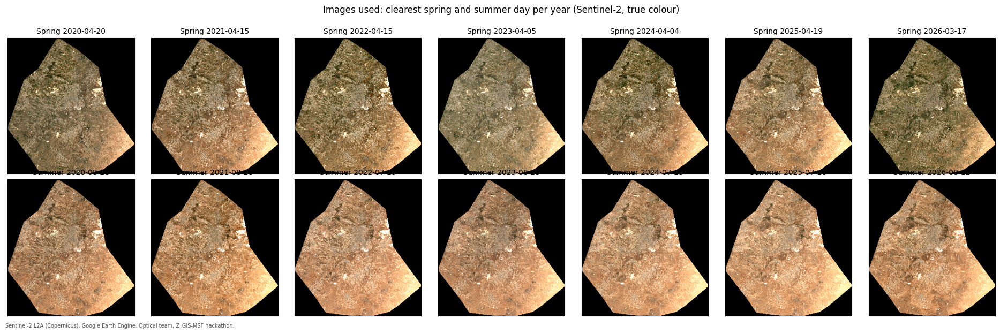

In [ ]:
# WHAT THIS CELL DOES
# Chooses the best spring and summer day of every year, builds the 14 images, saves the dates,
# and shows all images as labelled thumbnails (fetched in parallel).

SEASONS = [('spring', 'spring_window'), ('summer', 'summer_window')]

def day_table(y, key):
    start, end = window(y, key)
    rows = (S2.filterDate(start, end)
              .reduceColumns(ee.Reducer.toList(3), ['system:time_start', 'CLOUDY_PIXEL_PERCENTAGE', 'MGRS_TILE']).getInfo()['list'])
    df = pd.DataFrame(rows, columns=['t', 'cloud', 'tile'])
    df['date'] = pd.to_datetime(df.t, unit='ms').dt.strftime('%Y-%m-%d')
    g = df.groupby('date').agg(tiles=('tile', 'nunique'), cloud_pct=('cloud', 'mean')).reset_index()
    return g.sort_values(['tiles', 'cloud_pct'], ascending=[False, True]).reset_index(drop=True)

def one_day(date):
    nxt = (pd.Timestamp(date) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    return s2_masked(date, nxt).mosaic().divide(10000)

IMG, rows = {}, []
for y in YEARS:
    for season, key in SEASONS:
        days = day_table(y, key); assert len(days), f'No images for {season} {y}: widen CONFIG["{key}"].'
        main = CONFIG['image_dates'].get((y, season), days.date[0])
        fill = next((d for d in days.date if d != main), main)
        IMG[(y, season)] = ee.ImageCollection([one_day(fill), one_day(main)]).mosaic().clip(AOI)
        info = days[days.date == main]
        rows.append(dict(year=y, season=season, image_date=main, gaps_filled_from=fill, days_available=len(days),
                         scene_cloud_pct=round(float(info.cloud_pct.iloc[0]), 1) if len(info) else None))
image_dates = pd.DataFrame(rows); image_dates.to_csv(f'{OUT}/{nm("ImageDatesUsed")}.csv', index=False)
SUMMER_DATE = image_dates.query("season == 'summer'").set_index('year').image_date.to_dict()
display(image_dates.pivot(index='year', columns='season', values='image_date'))

jobs = [(IMG[(y, s)].visualize(**RGB), AOI_EXT, 300) for s, _ in SEASONS for y in YEARS]
pics = fetch(jobs)
fig, axes = plt.subplots(2, len(YEARS), figsize=(2.7 * len(YEARS), 6.2))
for k, (season, y) in enumerate([(s, y) for s, _ in SEASONS for y in YEARS]):
    d = image_dates[(image_dates.year == y) & (image_dates.season == season)].image_date.iloc[0]
    draw(axes[k // len(YEARS), k % len(YEARS)], pics[k], AOI_EXT, f'{season.capitalize()} {d}')
fig.suptitle('Images used: clearest spring and summer day per year (Sentinel-2, true colour)', fontsize=12)
caption(fig, SOURCE_NOTE); plt.tight_layout(rect=[0, 0.02, 1, 0.97]); plt.savefig(f'{OUT}/{nm("Fig_YearlyImages")}.png', dpi=160); plt.show()

# PART 1 – Buildings change

## 1.1 What the model looks at
Summer image: 10 bands + greenness (NDVI), built-up index (NDBI), bare-soil index (BSI), brightness. Spring image: the same four indices. Plus **spring-minus-summer greenness**, which separates fields (high) from roofs and rock (near zero).

In [ ]:
# WHAT THIS CELL DOES
# Combines the spring and summer image of each year into one feature image for the model.

def features(y):
    su = add_indices(IMG[(y, 'summer')])
    sp = (add_indices(IMG[(y, 'spring')]).select(['NDVI', 'NDBI', 'BSI', 'Brightness'])
          .rename(['NDVI_spring', 'NDBI_spring', 'BSI_spring', 'Brightness_spring']))
    return su.addBands(sp).addBands(sp.select('NDVI_spring').subtract(su.select('NDVI')).rename('dNDVI')).clip(AOI)

FEATS = {y: features(y) for y in YEARS}
FEATURE_NAMES = FEATS[Y0].bandNames()
print(len(FEATURE_NAMES.getInfo()), 'features per year:', FEATURE_NAMES.getInfo())

19 features per year: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDBI', 'BSI', 'Brightness', 'NDVI_spring', 'NDBI_spring', 'BSI_spring', 'Brightness_spring', 'dNDVI']


## 1.2 Training samples
Pixels where **WorldCover and Dynamic World agree in both 2020 and 2026** (unchanged); built-up samples must also lie on a **mapped building footprint**.

✏️ **Corrections:** where labels are wrong (often bare rock or quarries shown as built-up), draw a polygon and run `add_training('bare')` (or `'built'`, `'vegetation'`). Only where nothing changed 2020–2026. Then run the training cell. These polygons are also used by the independence test (1.11).

In [ ]:
# WHAT THIS CELL DOES
# Builds training labels from stable, agreeing pixels and shows them on a map with a legend.

def dw_label(y):
    '''Dynamic World most common class in the summer window: 0 built, 1 vegetation, 2 bare.'''
    return DW.filterDate(*window(y, 'summer_window')).select('label').mode().remap([0,1,2,3,4,5,6,7,8], [2,1,1,1,1,1,0,2,2])

wc3 = WORLDCOVER.remap([10,20,30,40,50,60,70,80,90,95,100], [1,1,1,1,0,2,2,2,1,1,2])
stable = wc3.eq(dw_label(Y0)).And(wc3.eq(dw_label(Y1)))

FOOTPRINTS_ID = 'projects/sat-io/open-datasets/VIDA_COMBINED/PSE'
try:
    ee.data.getAsset(FOOTPRINTS_ID)
    on_building = ee.Image(0).paint(ee.FeatureCollection(FOOTPRINTS_ID).filterBounds(AOI), 1).eq(1)
    print('Built-up samples restricted to mapped building footprints.')
except Exception:
    on_building = (DW.filterDate(*window(Y0, 'summer_window')).select('built').mean().gte(0.6)
                   .And(DW.filterDate(*window(Y1, 'summer_window')).select('built').mean().gte(0.6)))
    print('Footprint layer not available: built-up samples use a strict Dynamic World rule instead.')

labels = wc3.updateMask(stable.And(wc3.neq(0).Or(on_building))).rename('lc').clip(AOI)

EXTRA = []
train_map = geemap.Map(); train_map.add_basemap('HYBRID'); train_map.centerObject(AOI, 13)
train_map.addLayer(labels, {'min': 0, 'max': 2, 'palette': LC_PALETTE}, 'Training labels', True, 0.6)
train_map.addLayer(aoi_outline, {'palette': ['#ffff00']}, 'AOI')
train_map.add_legend(title='Training labels', legend_dict={**dict(zip(LC_NAMES, LC_PALETTE)), 'AOI': '#ffff00'}, position='bottomright')
train_map

Footprint layer not available: built-up samples use a strict Dynamic World rule instead.


Map(center=[31.48648612081326, 35.084253869130414], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# WHAT THIS CELL DOES
# ✏️ Stores one correction polygon. Draw on the map above, then run with the class that is really there.

def add_training(class_name):
    code = {'built': 0, 'vegetation': 1, 'bare': 2}[class_name]
    geom = train_map.user_roi; assert geom is not None, 'Draw a polygon on the map first.'
    EXTRA.append((geom, code)); print(f'{len(EXTRA)} correction area(s) stored; last one = {class_name}')

# add_training('bare')          # <- remove the # and run after drawing

6000 samples. Agreement with held-back samples: 0.910 | kappa 0.865  (not a field accuracy)
                      map Built-up  map Vegetation  map Bare
reference Built-up             547              42        29
reference Vegetation            42             545        21
reference Bare                  17              14       573


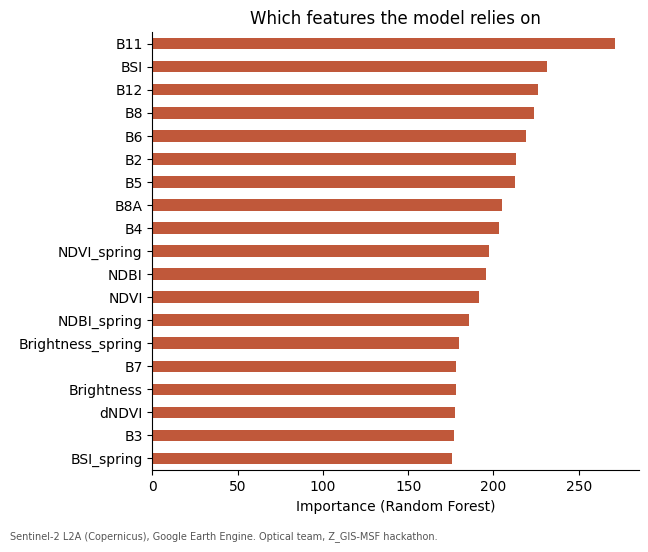

In [ ]:
# WHAT THIS CELL DOES
# Trains the Random Forest on samples from 2020 and 2026 (+ corrections counted double).
# The training samples are fetched ONCE and reused, so later maps and downloads do not retrain.

parts = [FEATS[y].addBands(labels).stratifiedSample(numPoints=CONFIG['n_train'] // 2, classBand='lc', region=AOI,
                                                    scale=SCALE, seed=y, tileScale=4, geometries=False) for y in (Y0, Y1)]
samples = parts[0].merge(parts[1])
if EXTRA:
    fc = ee.FeatureCollection([ee.Feature(g, {'lc': c}) for g, c in EXTRA])
    for y in (Y0, Y1):
        extra = FEATS[y].sampleRegions(collection=fc, properties=['lc'], scale=SCALE, tileScale=4).randomColumn('r', y).sort('r').limit(1500)
        samples = samples.merge(extra).merge(extra)
samples = samples.randomColumn('rnd', 42)
samples_cached, n_samples = fetch_fc(samples, keep=set(FEATURE_NAMES.getInfo()) | {'lc', 'rnd'})   # fetched once
train = samples_cached.filter(ee.Filter.lt('rnd', 0.7)); test = samples_cached.filter(ee.Filter.gte('rnd', 0.7))

rf_class = ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42).train(train, 'lc', FEATURE_NAMES)
rf_prob  = rf_class.setOutputMode('MULTIPROBABILITY')

cm = test.classify(rf_class).errorMatrix('lc', 'classification')
train_agreement, train_kappa = cm.accuracy().getInfo(), cm.kappa().getInfo()
print(f'{n_samples} samples. Agreement with held-back samples: {train_agreement:.3f} | kappa {train_kappa:.3f}  (not a field accuracy)')
print(pd.DataFrame(cm.getInfo(), index=[f'reference {n}' for n in LC_NAMES], columns=[f'map {n}' for n in LC_NAMES]))
imp = pd.Series(rf_class.explain().getInfo()['importance']).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 5.5)); imp.plot(kind='barh', ax=ax, color=C_TERRACOTTA)
ax.set_title('Which features the model relies on'); ax.set_xlabel('Importance (Random Forest)'); ax.spines[['top', 'right']].set_visible(False)
caption(fig, SOURCE_NOTE); plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig(f'{OUT}/{nm("Fig_FeatureImportance")}.png', dpi=180); plt.show()

## 1.3 Land cover for every year
The built-up line should be steady from year to year. Vegetation and bare swing with how wet each winter was; report **built-up change**, not the vegetation/bare split per year.

In [ ]:
# WHAT THIS CELL DOES
# Classifies every year and makes the area table and the 2020 -> 2026 change matrix (indicative).

LULC = {y: FEATS[y].classify(rf_class).rename('lc') for y in YEARS}
PROB = {y: FEATS[y].classify(rf_prob).arrayGet([0]).rename('p_built') for y in YEARS}

lc_areas = pd.DataFrame({y: grouped_area(LULC[y]) for y in YEARS}).T.fillna(0)
lc_areas.columns = [LC_NAMES[c] for c in lc_areas.columns]; lc_areas.index.name = 'year'
tr = grouped_area(LULC[Y0].multiply(10).add(LULC[Y1]))
matrix = pd.DataFrame([[tr.get(i * 10 + j, 0) for j in range(3)] for i in range(3)],
                      index=[f'{Y0} {n}' for n in LC_NAMES], columns=[f'{Y1} {n}' for n in LC_NAMES])
lc_areas.to_csv(f'{OUT}/{nm("LandCoverAreaByYear")}.csv'); matrix.to_csv(f'{OUT}/{nm("LandCoverChangeMatrix")}.csv')
print('Land cover per year (ha)'); display(lc_areas.round(0))
print(f'Change matrix {Y0} -> {Y1} (ha), single-year maps, indicative'); display(matrix.round(0))

Land cover per year (ha)


,Built-up,Vegetation,Bare
year,,,
2020,16806.0,35673.0,14901.0
2021,14199.0,30656.0,22536.0
2022,18614.0,26791.0,21987.0
2023,17908.0,32099.0,17385.0
2024,15916.0,28080.0,23396.0
2025,16160.0,20767.0,30465.0
2026,16634.0,33846.0,16911.0


Change matrix 2020 -> 2026 (ha), single-year maps, indicative


,2026 Built-up,2026 Vegetation,2026 Bare
2020 Built-up,12085.0,3272.0,1449.0
2020 Vegetation,3533.0,28409.0,3731.0
2020 Bare,1015.0,2161.0,11725.0


## 1.4 New built-up and built-up that disappeared
**New, confirmed (2021–2025):** clearly not built in 2020, built from year *y* and in every later year, clear probability rise, ≥ 5 pixels.
**New, provisional (2026):** built only in 2026 (orange).
**Disappeared:** built in 2020 and 2021, clear probability fall that persists, ≥ 5 pixels; **low confidence** inside dense town centres.

In [ ]:
# WHAT THIS CELL DOES
# Applies the change rules (as one function, reused by the independence test) and makes the yearly tables.

def build_change(PROB, LULC):
    p = CONFIG
    BUILT = {y: PROB[y].gte(p['p_built']) for y in YEARS}
    baseline = BUILT[Y0]
    was_open = PROB[Y0].lt(p['p_nonbuilt0']).And(LULC[Y0].neq(0))
    gain = PROB[Y1].add(PROB[Y1 - 1]).divide(2).subtract(PROB[Y0]).gte(p['min_gain'])
    def stays(y):
        out = BUILT[y]
        for k in range(y + 1, Y1 + 1): out = out.And(BUILT[k])
        return out
    year_new = (ee.ImageCollection([ee.Image.constant(y).toInt16().updateMask(stays(y)) for y in CONFIRMED_YEARS])
                .min().updateMask(was_open.And(gain)).rename('year_new_built'))
    year_new = keep_patches(year_new, p['min_pixels']).clip(AOI)
    new_built = year_new.gt(0).selfMask()
    prov = BUILT[Y1].And(was_open).And(PROB[Y1].subtract(PROB[Y0]).gte(p['min_gain'])).And(year_new.unmask(0).eq(0))
    prov = keep_patches(prov.selfMask(), p['min_pixels']).clip(AOI)
    from_class = LULC[Y0].rename('from_class')
    solid_start = PROB[Y0].gte(0.6).And(PROB[Y0 + 1].gte(0.6))
    def gone(y):
        out = ee.Image(1)
        for k in range(y, Y1 + 1): out = out.And(PROB[Y0].subtract(PROB[k]).gte(p['loss_drop'])).And(PROB[k].lt(0.4))
        return out
    year_lost = (ee.ImageCollection([ee.Image.constant(y).toInt16().updateMask(gone(y)) for y in YEARS[2:]])
                 .min().updateMask(solid_start).rename('year_built_lost'))
    year_lost = keep_patches(year_lost, p['min_pixels']).clip(AOI)
    built_lost = year_lost.gt(0).selfMask()
    dense = baseline.unmask(0).reduceNeighborhood(ee.Reducer.mean(), ee.Kernel.square(2)).gte(p['dense_share'])
    loss_conf = ee.Image(1).where(dense, 2).updateMask(built_lost).rename('confidence')
    return dict(BUILT=BUILT, baseline=baseline, year_new=year_new, new_built=new_built, provisional=prov, from_class=from_class,
                bare_to_built=new_built.updateMask(from_class.eq(2)), year_lost=year_lost, built_lost=built_lost, loss_conf=loss_conf)

R = build_change(PROB, LULC)
BUILT, baseline, year_new, new_built, provisional, from_class, bare_to_built, year_lost, built_lost, loss_conf = (
    R[k] for k in ['BUILT', 'baseline', 'year_new', 'new_built', 'provisional', 'from_class', 'bare_to_built', 'year_lost', 'built_lost', 'loss_conf'])

by   = grouped_area(year_new.multiply(10).add(from_class.updateMask(new_built)))
prov = grouped_area(from_class.updateMask(provisional))
stats = pd.DataFrame({'from_bare_ha':       {**{y: by.get(y * 10 + 2, 0) for y in CONFIRMED_YEARS}, Y1: prov.get(2, 0)},
                      'from_vegetation_ha': {**{y: by.get(y * 10 + 1, 0) for y in CONFIRMED_YEARS}, Y1: prov.get(1, 0)}})
stats['new_built_ha'] = stats.sum(axis=1)
stats['status'] = ['provisional' if y == Y1 else 'confirmed' for y in stats.index]; stats.index.name = 'year'
base_ha = grouped_area(baseline.selfMask()).get(1, 0)
stats['cumulative_confirmed_ha'] = (base_ha + stats.loc[CONFIRMED_YEARS, 'new_built_ha'].cumsum()).reindex(stats.index)
conf = stats.loc[CONFIRMED_YEARS]; stats.to_csv(f'{OUT}/{nm("NewBuiltupStats")}.csv')

lc = grouped_area(year_lost.multiply(10).add(loss_conf))
lost_stats = pd.DataFrame({'clear_ha': {y: lc.get(y * 10 + 1, 0) for y in YEARS[2:]}, 'low_confidence_ha': {y: lc.get(y * 10 + 2, 0) for y in YEARS[2:]}})
lost_stats['status'] = ['provisional' if y == Y1 else 'confirmed' for y in lost_stats.index]; lost_stats.index.name = 'year'
lost_stats.to_csv(f'{OUT}/{nm("BuiltupDisappearedStats")}.csv')

print(f'Built-up {Y0}: {base_ha:,.0f} ha ({base_ha / (area_km2 * 100) * 100:.1f} % of AOI)')
print(f'New built-up {CONFIRMED_YEARS[0]}-{CONFIRMED_YEARS[-1]} (confirmed): {conf.new_built_ha.sum():,.0f} ha, '
      f'{conf.from_bare_ha.sum() / max(conf.new_built_ha.sum(), 1e-9) * 100:.0f} % on bare land | {Y1} provisional: {stats.loc[Y1, "new_built_ha"]:,.0f} ha')
display(stats.round(1)); display(lost_stats.round(2))

Built-up 2020: 12,749 ha (18.9 % of AOI)
New built-up 2021-2025 (confirmed): 177 ha, 38 % on bare land | 2026 provisional: 274 ha


,from_bare_ha,from_vegetation_ha,new_built_ha,status,cumulative_confirmed_ha
year,,,,,
2021,15.8,9.8,25.6,confirmed,12774.7
2022,10.5,14.7,25.3,confirmed,12800.0
2023,16.8,22.0,38.9,confirmed,12838.8
2024,7.0,25.6,32.5,confirmed,12871.4
2025,16.5,38.5,54.9,confirmed,12926.3
2026,78.0,195.5,273.5,provisional,NaN


,clear_ha,low_confidence_ha,status
year,,,
2022,0.10,0.41,confirmed
2023,1.19,0.44,confirmed
2024,4.83,3.06,confirmed
2025,4.42,3.30,confirmed
2026,9.82,6.93,provisional


In [ ]:
# WHAT THIS CELL DOES
# Interactive map of Part 1 with a legend. Switch layers on and off (top right).

m1 = geemap.Map(); m1.add_basemap('HYBRID'); m1.centerObject(AOI, 13)
lcv = {'min': 0, 'max': 2, 'palette': LC_PALETTE}
m1.addLayer(IMG[(Y0, 'summer')], RGB, f'Sentinel-2 summer {Y0}', False); m1.addLayer(IMG[(Y1, 'summer')], RGB, f'Sentinel-2 summer {Y1}', False)
m1.addLayer(LULC[Y0], lcv, f'Land cover {Y0}', False); m1.addLayer(LULC[Y1], lcv, f'Land cover {Y1}', False)
m1.addLayer(baseline.selfMask(), {'palette': [C_CHARCOAL]}, f'Built-up {Y0}', True, 0.5)
m1.addLayer(loss_conf, {'min': 1, 'max': 2, 'palette': [C_LOST, C_LOST_LOW]}, 'Built-up disappeared')
m1.addLayer(year_new, {'min': CONFIRMED_YEARS[0], 'max': CONFIRMED_YEARS[-1], 'palette': YEAR_PALETTE}, 'New built-up by year', False)
m1.addLayer(provisional, {'palette': [C_PROV]}, f'New built-up {Y1} (provisional)')
m1.addLayer(new_built, {'palette': [C_RED]}, 'New built-up 2021-2025 (confirmed)')
m1.addLayer(aoi_outline, {'palette': ['#ffff00']}, 'AOI')
m1.add_legend(title='Built-up change 2020-2026', position='bottomright', legend_dict={
    f'Built-up {Y0}': C_CHARCOAL, 'New built-up 2021-2025 (confirmed)': C_RED, f'New built-up {Y1} (provisional)': C_PROV,
    'Built-up disappeared (clear)': C_LOST, 'Built-up disappeared (low confidence)': C_LOST_LOW, 'AOI': '#ffff00'})
m1

Map(center=[31.486486120813037, 35.0842538691304], controls=(WidgetControl(options=['position', 'transparent_b…

## 1.5 Compute once, download once
All final rasters are stacked and downloaded **once**, as tiles in parallel. Earth Engine runs the classification one time; polygons, hotspots, validation points, focus-area statistics and the comparison with existing products are then made **locally** in Colab. Band codes are in the README.

In [ ]:
# WHAT THIS CELL DOES
# Builds the results stack, downloads it once (parallel tiles), loads it, and makes the polygons locally.

BANDS = [f'landcover_{y}' for y in YEARS] + ['new_year', 'new_2026_provisional', 'bare_to_built', 'built_2020',
          'lost_year', 'lost_confidence', 'dw_built_2020', 'dw_built_2026', 'wc_built_2021']
stack = ee.Image.cat([LULC[y].add(1).rename(f'landcover_{y}') for y in YEARS] + [           # land cover stored as 1 built, 2 vegetation, 3 bare (0 = outside)
    year_new.subtract(2000).rename('new_year'), provisional.rename('new_2026_provisional'), bare_to_built.rename('bare_to_built'),
    baseline.selfMask().rename('built_2020'), year_lost.subtract(2000).rename('lost_year'), loss_conf.rename('lost_confidence'),
    dw_label(Y0).eq(0).rename('dw_built_2020'), dw_label(Y1).eq(0).rename('dw_built_2026'), WORLDCOVER.eq(50).rename('wc_built_2021')
]).unmask(0).clip(AOI).unmask(0, False).toUint8()

STACK_PATH = f'{OUT}/{nm("ResultsStack_2020_2026")}.tif'
t0 = time.time(); download_tiled(stack, STACK_PATH); print(f'  download took {time.time() - t0:.0f} s')

with rasterio.open(STACK_PATH) as src:
    A = src.read(); TR, CRS, SHAPE = src.transform, src.crs, (src.height, src.width)
L = {name: A[i] for i, name in enumerate(BANDS)}
INSIDE = L['landcover_2020'] > 0
PX_HA = SCALE * SCALE / 1e4

def patches_from(mask, extra):
    '''Groups touching pixels (8-neighbour) into polygons with per-patch statistics. extra = {name: (array, 'mean'|'minimum'|'maximum')}.'''
    lab, n = ndimage.label(mask, structure=np.ones((3, 3)))
    if n == 0: return gpd.GeoDataFrame(columns=['patch_id', 'area_ha', 'geometry'], geometry='geometry', crs=4326)
    idx = np.arange(1, n + 1)
    data = {'patch_id': idx, 'area_ha': ndimage.sum(mask, lab, idx) * PX_HA}
    for k, (arr, how) in extra.items(): data[k] = getattr(ndimage, how)(arr, lab, idx)
    geoms = {}
    for g, v in rasterio.features.shapes(lab.astype('int32'), mask=lab > 0, transform=TR, connectivity=8):
        geoms.setdefault(int(v), []).append(shape(g))
    gdf = gpd.GeoDataFrame(pd.DataFrame(data), geometry=[unary_union(geoms[i]) for i in idx], crs=CRS)
    cen = gdf.geometry.centroid.to_crs(4326); gdf['lon'], gdf['lat'] = cen.x.round(5), cen.y.round(5)
    return gdf.to_crs(4326)

new_patches = patches_from(L['new_year'] > 0, {'year': (L['new_year'].astype(float) + 2000, 'minimum'),
                                               'bare_share': ((L['landcover_2020'] == 3).astype(float), 'mean'),
                                               'dw_built_2026_share': (L['dw_built_2026'].astype(float), 'mean')})
new_patches['replaced'] = np.where(new_patches.get('bare_share', 0) > 0.5, 'bare', 'vegetation') if len(new_patches) else []
new_patches['dw_agrees'] = new_patches.get('dw_built_2026_share', 0) >= 0.5 if len(new_patches) else []
prov_patches = patches_from(L['new_2026_provisional'] > 0, {'bare_share': ((L['landcover_2020'] == 3).astype(float), 'mean')})
lost_patches = patches_from(L['lost_year'] > 0, {'year': (L['lost_year'].astype(float) + 2000, 'minimum'),
                                                 'low_conf_share': ((L['lost_confidence'] == 2).astype(float), 'mean')})
if len(lost_patches): lost_patches['confidence'] = np.where(lost_patches.low_conf_share > 0.5, 'low (dense town)', 'clear')

hot = new_patches[new_patches.replaced == 'bare'].nlargest(CONFIG['n_hotspots'], 'area_ha') if len(new_patches) else new_patches
HOTSPOTS = [dict(name=f'Hotspot {i + 1}', lon=r.lon, lat=r.lat, area_ha=r.area_ha, year=int(r.year)) for i, (_, r) in enumerate(hot.iterrows())]
print(f'{len(new_patches)} confirmed new built-up patches, {len(prov_patches)} provisional, {len(lost_patches)} disappeared; hotspots:')
display(pd.DataFrame(HOTSPOTS))

  tiles 11/12

  tiles 12/12


  saved hebron_change_detection_v3_outputs/PSE_Hebron_S2_ResultsStack_2020_2026.tif
  download took 139 s
3200 confirmed new built-up patches, 4756 provisional, 808 disappeared; hotspots:


,name,lon,lat,area_ha,year
0,Hotspot 1,35.00564,31.37201,2.65,2022
1,Hotspot 2,35.11525,31.50361,2.18,2021
2,Hotspot 3,35.04562,31.49327,1.91,2021
3,Hotspot 4,35.08293,31.49190,1.57,2021


In [ ]:
# WHAT THIS CELL DOES
# Replaces the 20 m preview tables with the official 10 m statistics from the downloaded stack.
# Charts, focus areas and the README below then use these numbers.

ny, lc20, pv, ly, lcf = L['new_year'], L['landcover_2020'], L['new_2026_provisional'], L['lost_year'], L['lost_confidence']
rows = {y: dict(from_bare_ha=((ny == y - 2000) & (lc20 == 3)).sum() * PX_HA,
                from_vegetation_ha=((ny == y - 2000) & (lc20 == 2)).sum() * PX_HA) for y in CONFIRMED_YEARS}
rows[Y1] = dict(from_bare_ha=((pv == 1) & (lc20 == 3)).sum() * PX_HA, from_vegetation_ha=((pv == 1) & (lc20 == 2)).sum() * PX_HA)
stats = pd.DataFrame(rows).T; stats.index.name = 'year'
stats['new_built_ha'] = stats.from_bare_ha + stats.from_vegetation_ha
stats['status'] = ['provisional' if y == Y1 else 'confirmed' for y in stats.index]
base_ha = (L['built_2020'] == 1).sum() * PX_HA
stats['cumulative_confirmed_ha'] = (base_ha + stats.loc[CONFIRMED_YEARS, 'new_built_ha'].cumsum()).reindex(stats.index)
conf = stats.loc[CONFIRMED_YEARS]
lost_stats = pd.DataFrame({y: dict(clear_ha=((ly == y - 2000) & (lcf == 1)).sum() * PX_HA,
                                   low_confidence_ha=((ly == y - 2000) & (lcf == 2)).sum() * PX_HA) for y in YEARS[2:]}).T
lost_stats.index.name = 'year'; lost_stats['status'] = ['provisional' if y == Y1 else 'confirmed' for y in lost_stats.index]
lc_areas = pd.DataFrame({y: {n: (L[f'landcover_{y}'] == i + 1).sum() * PX_HA for i, n in enumerate(LC_NAMES)} for y in YEARS}).T
lc_areas.index.name = 'year'
stats.to_csv(f'{OUT}/{nm("NewBuiltupStats")}.csv'); lost_stats.to_csv(f'{OUT}/{nm("BuiltupDisappearedStats")}.csv')
lc_areas.to_csv(f'{OUT}/{nm("LandCoverAreaByYear")}.csv')
print(f'Official 10 m: built-up {Y0} {base_ha:,.0f} ha | new {CONFIRMED_YEARS[0]}-{CONFIRMED_YEARS[-1]} confirmed {conf.new_built_ha.sum():,.0f} ha '
      f'({conf.from_bare_ha.sum() / max(conf.new_built_ha.sum(), 1e-9) * 100:.0f} % on bare) | {Y1} provisional {stats.loc[Y1, "new_built_ha"]:,.0f} ha')
display(stats.round(1)); display(lost_stats.round(2))

Official 10 m: built-up 2020 12,765 ha | new 2021-2025 confirmed 351 ha (33 % on bare) | 2026 provisional 431 ha


,from_bare_ha,from_vegetation_ha,new_built_ha,status,cumulative_confirmed_ha
year,,,,,
2021,27.0,26.2,53.2,confirmed,12818.6
2022,17.8,33.4,51.2,confirmed,12869.8
2023,28.6,43.9,72.5,confirmed,12942.3
2024,12.6,52.0,64.6,confirmed,13006.9
2025,29.1,80.0,109.0,confirmed,13115.9
2026,115.5,315.4,430.8,provisional,NaN


,clear_ha,low_confidence_ha,status
year,,,
2022,0.74,0.99,confirmed
2023,2.37,2.65,confirmed
2024,8.13,8.62,confirmed
2025,7.27,9.04,confirmed
2026,16.35,21.97,provisional


## 1.6 How different are we from the existing products?
Answers the existing-products team with numbers: how much of the area was used for training, how much our maps agree with Dynamic World and WorldCover, and **how much of our new built-up Dynamic World also shows as new**. The disagreement map shows where to look on high-resolution imagery.

,comparison,both_built_ha,only_ours_ha,only_product_ha,pixel_agreement_pct,built_overlap_pct
0,Ours 2020 vs Dynamic World 2020,13015.2,3823.5,9826.4,79.8,48.8
1,Ours 2021 vs WorldCover 2021,8019.7,6188.8,2491.2,87.1,48.0
2,Ours 2026 vs Dynamic World 2026,14252.0,2387.8,12291.8,78.2,49.3


,value
Training pixels actually used,6000.000
Training pixels as share of AOI pixels (%),0.089
Eligible pool: pixels where products agree 2020 and 2026 (% of AOI),47.516
Our confirmed new built-up (ha),350.590
Dynamic World new built-up 2020->2026 (ha),4844.420
Share of our new built-up that Dynamic World also shows as new (%),25.363
Share of our new built-up that Dynamic World already called built in 2020 (%),61.642


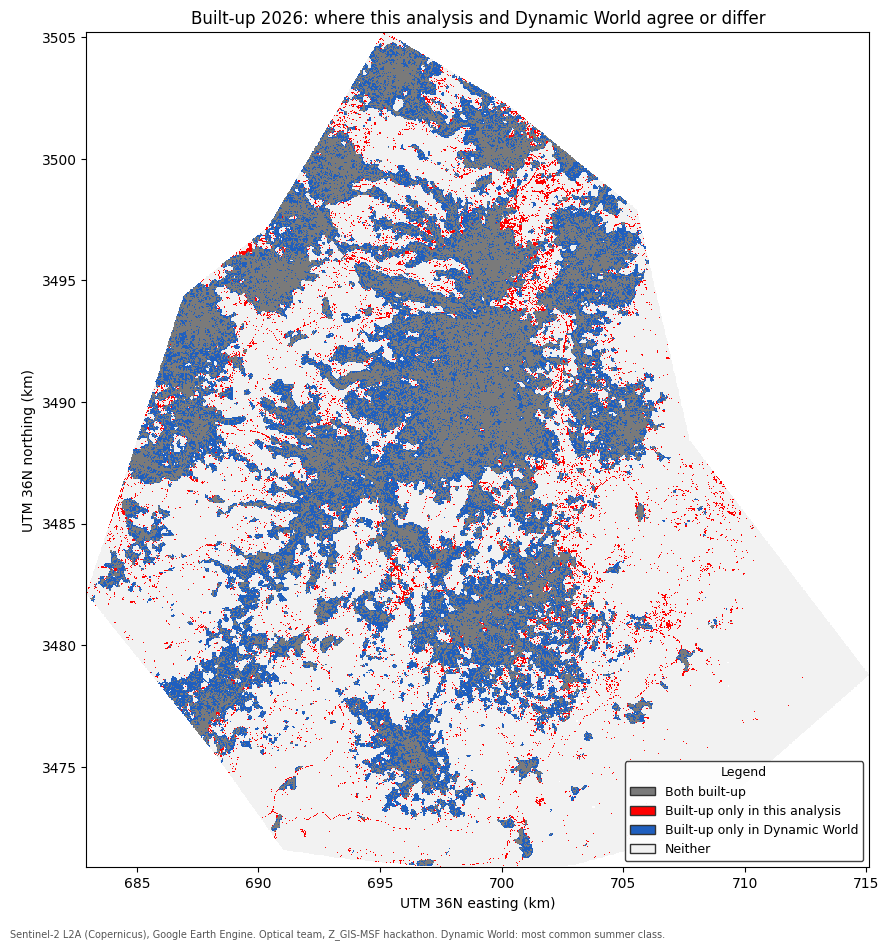

In [ ]:
# WHAT THIS CELL DOES
# Compares our maps with Dynamic World and WorldCover (locally, from the downloaded stack) and draws a disagreement map.
# Reports the training pixels actually used AND the eligible pool, so the two are not confused.

train_px = labels.reduceRegion(ee.Reducer.count(), AOI, 30, maxPixels=1e10, tileScale=4).getInfo().get('lc', 0)   # eligible pool (30 m pixels)
aoi_px30 = area_km2 * 1e6 / 900
ours = {y: L[f'landcover_{y}'] == 1 for y in YEARS}

def compare(a, b, name_a, name_b):
    both, only_a, only_b = (a & b & INSIDE).sum(), (a & ~b & INSIDE).sum(), (~a & b & INSIDE).sum()
    agree = ((a == b) & INSIDE).sum() / INSIDE.sum()
    return {'comparison': f'{name_a} vs {name_b}', 'both_built_ha': both * PX_HA, 'only_ours_ha': only_a * PX_HA,
            'only_product_ha': only_b * PX_HA, 'pixel_agreement_pct': agree * 100,
            'built_overlap_pct': both / max(both + only_a + only_b, 1) * 100}

rows = [compare(ours[Y0], L['dw_built_2020'] == 1, f'Ours {Y0}', f'Dynamic World {Y0}'),
        compare(ours[2021], L['wc_built_2021'] == 1, 'Ours 2021', 'WorldCover 2021'),
        compare(ours[Y1], L['dw_built_2026'] == 1, f'Ours {Y1}', f'Dynamic World {Y1}')]
diff_table = pd.DataFrame(rows).round(1)

our_new = L['new_year'] > 0
dw_new = (L['dw_built_2026'] == 1) & (L['dw_built_2020'] == 0) & INSIDE
summary = pd.Series({
    'Training pixels actually used': n_samples,
    'Training pixels as share of AOI pixels (%)': n_samples / INSIDE.sum() * 100,
    'Eligible pool: pixels where products agree 2020 and 2026 (% of AOI)': train_px / aoi_px30 * 100,
    'Our confirmed new built-up (ha)': our_new.sum() * PX_HA,
    'Dynamic World new built-up 2020->2026 (ha)': dw_new.sum() * PX_HA,
    'Share of our new built-up that Dynamic World also shows as new (%)': (our_new & dw_new).sum() / max(our_new.sum(), 1) * 100,
    'Share of our new built-up that Dynamic World already called built in 2020 (%)': (our_new & (L['dw_built_2020'] == 1)).sum() / max(our_new.sum(), 1) * 100,
}).round(3)
diff_table.to_csv(f'{OUT}/{nm("Comparison_ExistingProducts")}.csv', index=False); summary.to_csv(f'{OUT}/{nm("Comparison_Summary")}.csv')
display(diff_table); display(summary.to_frame('value'))

# Disagreement map 2026 (local, downsampled for display)
cat = np.zeros(SHAPE, np.uint8)
cat[INSIDE] = 1
cat[ours[Y1] & (L['dw_built_2026'] == 1)] = 2
cat[ours[Y1] & (L['dw_built_2026'] == 0) & INSIDE] = 3
cat[~ours[Y1] & (L['dw_built_2026'] == 1)] = 4
f = 3; small = cat[::f, ::f]
ext_km = [TR.c / 1000, (TR.c + SHAPE[1] * SCALE) / 1000, (TR.f - SHAPE[0] * SCALE) / 1000, TR.f / 1000]
fig, ax = plt.subplots(figsize=(9, 9.5))
ax.imshow(np.ma.masked_equal(small, 0), cmap=ListedColormap(['#f2f2f2', '#7a7a7a', C_RED, C_BLUE]), vmin=1, vmax=4,
          extent=ext_km, interpolation='nearest')
ax.set_xlabel('UTM 36N easting (km)'); ax.set_ylabel('UTM 36N northing (km)')
ax.set_title(f'Built-up {Y1}: where this analysis and Dynamic World agree or differ', fontsize=12)
legend(ax, [('Both built-up', '#7a7a7a'), ('Built-up only in this analysis', C_RED),
            ('Built-up only in Dynamic World', C_BLUE), ('Neither', '#f2f2f2')], loc='lower right', fontsize=9, title='Legend')
caption(fig, SOURCE_NOTE + ' Dynamic World: most common summer class.'); plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.savefig(f'{OUT}/{nm("Map_Disagreement_DynamicWorld_2026")}.png', dpi=200); plt.show()

## 1.7 Reported places: zoom in where building is reported
✏️ Add places by **name** (`search=` for alternative spellings), **coordinates**, **drawing** on the Part 1 map, or **file upload** (KMZ / KML / GeoJSON; points or polygons; a year in the name like `Mount Tarusa | 2026` is read automatically). Pre-loaded: MSF focus communities, settlements named on the slide map, and reported construction sites. Check the labelled confirmation map.

**Detected** = a confirmed (2021–2025) new built-up group of ≥ 5 pixels inside the place. 2026 (orange) never makes a place "detected".

In [ ]:
# WHAT THIS CELL DOES
# ✏️ Builds the list of reported places (fresh each run) and shows them on a labelled map.

PLACES = []

def add_place(name, lat=None, lon=None, year=None, source='', radius_m=None, search=None, geom=None):
    if geom is not None:
        c = geom.centroid; lat, lon = c.y, c.x; eg = to_ee_geom(geom, radius_m or CONFIG['site_radius_m'])
    else:
        if lat is None or lon is None:
            hit = lookup(*(search if isinstance(search, (list, tuple)) else [search or name]))
            if hit is None: print(f'  not found: {name} -> add lat= and lon=, draw it, or upload a file'); return
            lat, lon = hit
        eg = ee.Geometry.Point([lon, lat]).buffer(radius_m or CONFIG['site_radius_m'])
    PLACES.append(dict(name=name, lat=lat, lon=lon, reported_year=year, source=source, geom=eg)); print(f'  added {name}: {lat:.4f}, {lon:.4f}')

def add_place_drawn(name, year=None, source=''):
    geom = m1.user_roi; assert geom is not None, 'Draw a polygon on the Part 1 map first.'
    c = geom.centroid(1).coordinates().getInfo()
    PLACES.append(dict(name=name, lat=c[1], lon=c[0], reported_year=year, source=source, geom=geom)); print(f'  added {name} (drawn)')

def add_places_file(radius_m=None):
    '''Upload KMZ / KML / GeoJSON / GeoPackage with places (points or polygons).'''
    up = files.upload()
    for p in up.keys():
        for _, r in read_features(p).iterrows():
            nmcol = r.get('Name', r.get('name', os.path.splitext(p)[0])); d = find_date(r)
            add_place(clean_name(nmcol), year=int(d[:4]) if d else None, source=f'file {p}', radius_m=radius_m, geom=r.geometry)

FOCUS_COMMUNITIES = ['Jinba', 'Khirbet al Fakheit', 'At Tabban', 'Al Mirkez', 'Ad Deirat', "Ir Rifa'iya", 'Qilqis',
                     'Dura', 'Beit Ummar', "Sa'ir", 'Birin']
SETTLEMENTS = ['Kiryat Arba', 'Pnei Hever', 'Carmel', "Ma'on", 'Otniel']
for n in FOCUS_COMMUNITIES: add_place(n, source='MSF brief focus area', radius_m=500)
for n in SETTLEMENTS:       add_place(n, source='hackathon slide map', radius_m=600)
add_place('Karmei Tzur / Beit Ummar lands', search=['Karmei Tzur', 'Karme Zur'], radius_m=700, source='IMEMC (bulldozing for expansion)')
add_place('Mount Tarusa (Doren)', search=['Jabal Tarusa', 'Tarusa', 'Mount Tarousa'], year=2026, radius_m=500, source='WAFA 17 Jun 2026')

# ✏️ more:  add_place('Name', lat=..., lon=..., year=2025, source='...')   or   add_places_file()

mp = geemap.Map(); mp.add_basemap('HYBRID'); mp.centerObject(AOI, 11)
mp.addLayer(aoi_outline, {'palette': ['#ffff00']}, 'AOI')
for p in PLACES: mp.addLayer(outline(p['geom'], '#ffffff', 2), {}, p['name']); map_label(mp, p['lat'], p['lon'], p['name'])
for h in HOTSPOTS: map_label(mp, h['lat'], h['lon'], f"{h['name']} ({h['area_ha']:.1f} ha)")
mp.add_legend(title='Places', legend_dict={'Reported place (circle)': '#ffffff', 'AOI': '#ffff00'}, position='bottomright')
print(f'{len(PLACES)} place(s); hotspots labelled too. Check each label:'); mp

  added Jinba: 31.3632, 35.1398
  not found: Khirbet al Fakheit -> add lat= and lon=, draw it, or upload a file
  not found: At Tabban -> add lat= and lon=, draw it, or upload a file
  added Al Mirkez: 31.3630, 35.1508
  added Ad Deirat: 31.4446, 35.1586
  not found: Ir Rifa'iya -> add lat= and lon=, draw it, or upload a file
  not found: Qilqis -> add lat= and lon=, draw it, or upload a file
  added Dura: 31.5066, 35.0264
  added Beit Ummar: 31.6210, 35.1031
  added Sa'ir: 31.5829, 35.1452
  added Birin: 31.4900, 35.1363
  added Kiryat Arba: 31.5434, 35.1206
  not found: Pnei Hever -> add lat= and lon=, draw it, or upload a file
  added Carmel: 31.4309, 35.1833
  added Ma'on: 31.4140, 35.1629
  added Otniel: 31.7623, 35.2220
  added Karmei Tzur / Beit Ummar lands: 31.6092, 35.1009
  added Mount Tarusa (Doren): 31.5253, 34.9837
13 place(s); hotspots labelled too. Check each label:


Map(center=[31.48648612081326, 35.084253869130414], controls=(WidgetControl(options=['position', 'transparent_…

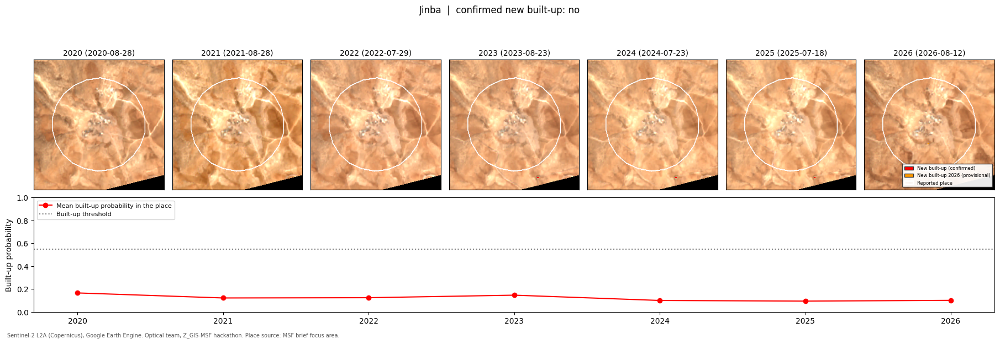

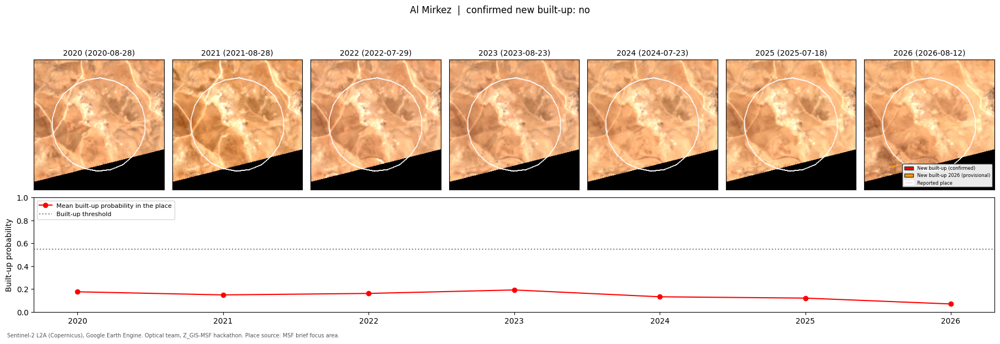

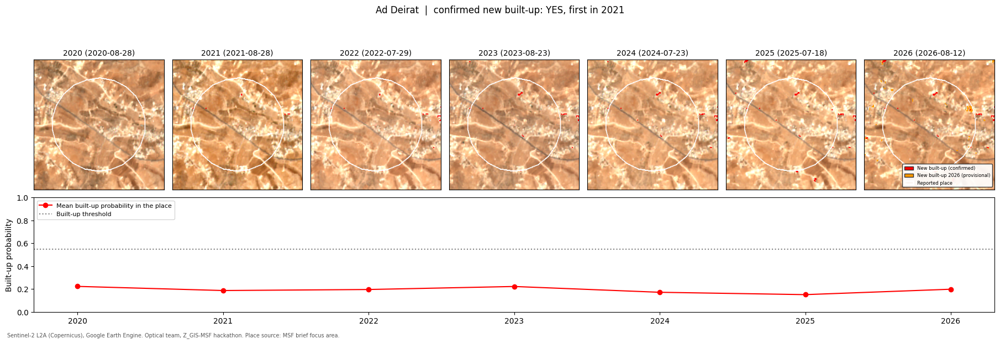

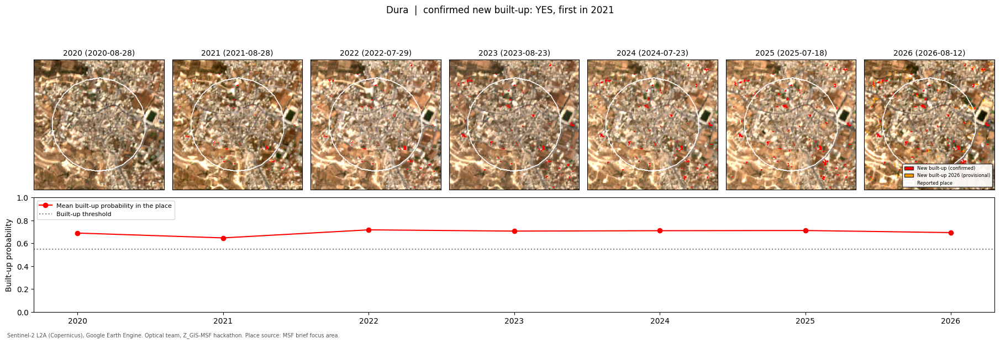

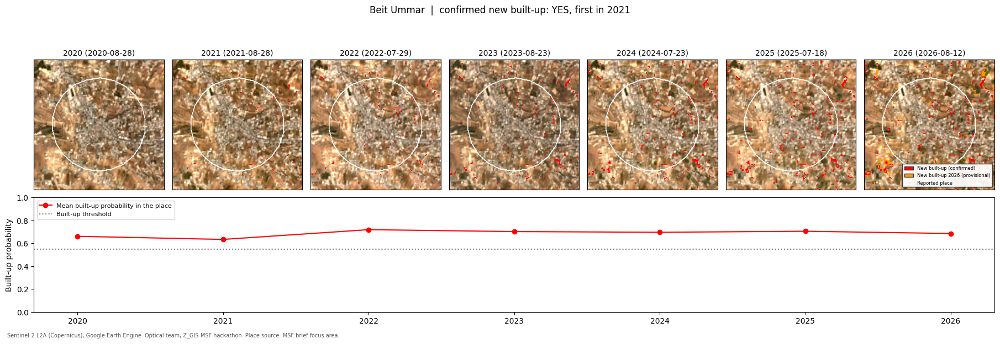

...

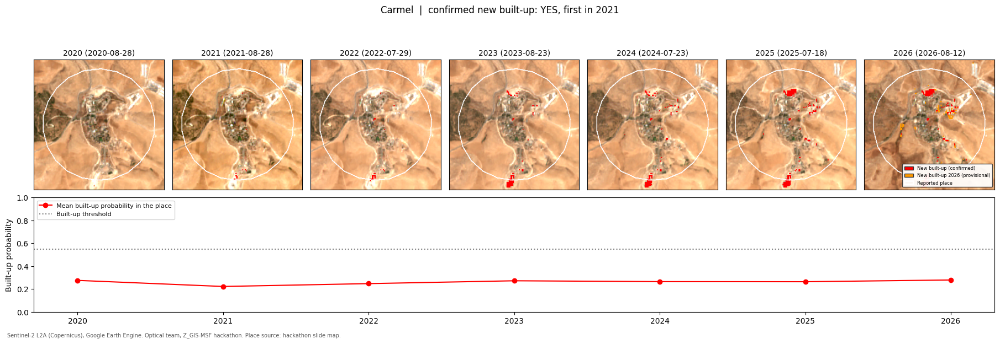

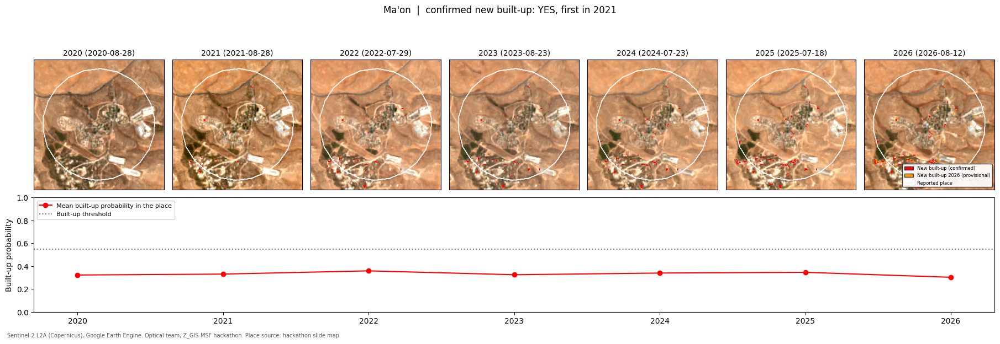

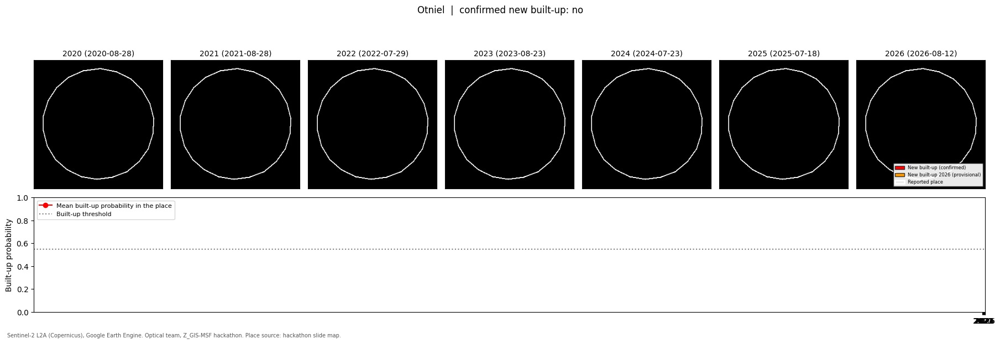

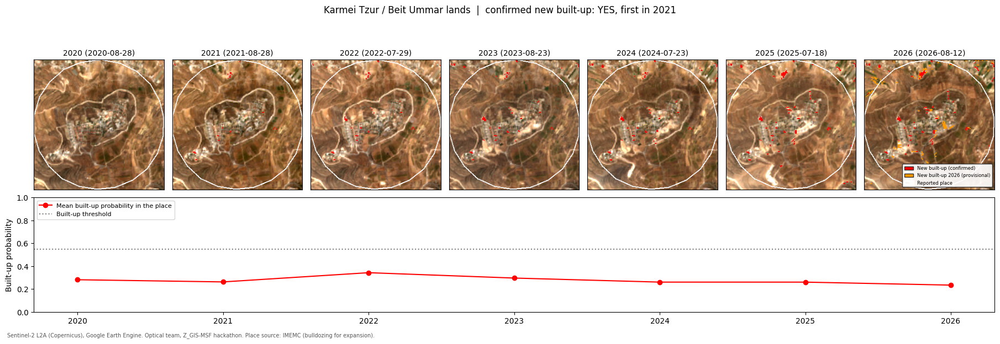

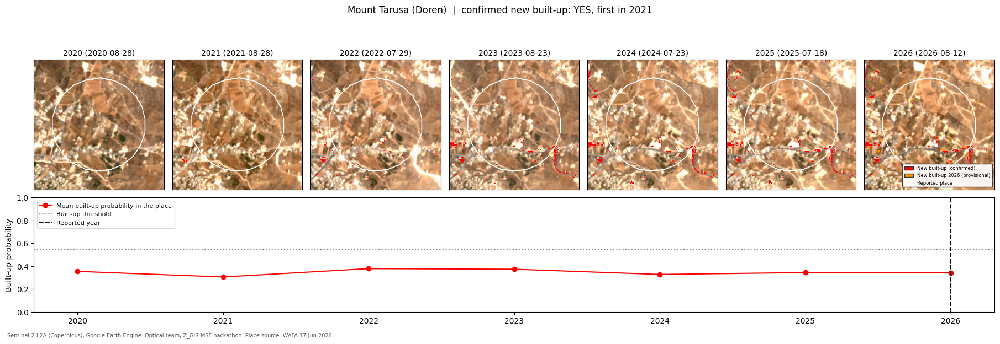

Confirmed new built-up at 10 of 13 places


,name,lat,lon,reported_year,source,detected,first_year,bare_to_built_ha,built_2020_ha,built_lost_ha,new_2026_provisional_ha,new_confirmed_ha,p_built_2020,p_built_2026
0,Jinba,31.36316,35.13984,NaN,MSF brief focus area,False,NaN,0.00,2.95,0.00,0.00,0.00,0.17,0.10
1,Al Mirkez,31.36302,35.15082,NaN,MSF brief focus area,False,NaN,0.00,3.46,0.00,0.00,0.00,0.18,0.07
2,Ad Deirat,31.44456,35.15864,NaN,MSF brief focus area,True,2021.0,0.11,6.19,0.00,0.44,0.11,0.22,0.20
3,Dura,31.50660,35.02637,NaN,MSF brief focus area,True,2021.0,0.07,54.36,0.02,0.33,0.59,0.69,0.69
4,Beit Ummar,31.62101,35.10309,NaN,MSF brief focus area,True,2021.0,0.03,51.06,0.03,0.44,0.67,0.66,0.69
5,Sa'ir,31.58293,35.14522,NaN,MSF brief focus area,True,2021.0,0.00,51.75,0.04,0.26,0.20,0.66,0.65
6,Birin,31.49001,35.13634,NaN,MSF brief focus area,True,2021.0,0.48,9.75,0.00,1.05,0.88,0.26,0.28
7,Kiryat Arba,31.54342,35.12056,NaN,hackathon slide map,True,2021.0,0.67,52.98,0.87,0.61,1.24,0.52,0.52
8,Carmel,31.43087,35.18330,NaN,hackathon slide map,True,2021.0,1.13,20.24,0.24,1.00,1.30,0.28,0.28
9,Ma'on,31.41399,35.16286,NaN,hackathon slide map,True,2021.0,0.00,26.19,0.07,0.55,0.55,0.32,0.30


In [ ]:
# WHAT THIS CELL DOES
# For each place: summer image of every year with new built-up (red confirmed, orange 2026 provisional),
# the built-up probability curve, a legend, and a results table. Pictures are fetched in parallel.

prob_stack = ee.Image.cat([PROB[y].rename(f'p_{y}') for y in YEARS])
area_stack = (HA.updateMask(baseline).rename('built_2020_ha').addBands(HA.updateMask(new_built).rename('new_confirmed_ha'))
              .addBands(HA.updateMask(bare_to_built).rename('bare_to_built_ha')).addBands(HA.updateMask(provisional).rename('new_2026_provisional_ha'))
              .addBands(HA.updateMask(built_lost).rename('built_lost_ha')))
place_leg = [('New built-up (confirmed)', C_RED), (f'New built-up {Y1} (provisional)', C_PROV), ('Reported place', '#ffffff', 'outline')]

def check_place(p):
    g = p['geom']
    pr = prob_stack.reduceRegion(ee.Reducer.mean(), g, SCALE).getInfo()
    a  = area_stack.reduceRegion(ee.Reducer.sum(), g, SCALE).getInfo()
    yr = year_new.reduceRegion(ee.Reducer.min(), g, SCALE).getInfo().get('year_new_built')
    ext = bbox(p['lon'], p['lat'], CONFIG['zoom_half_m'])
    jobs = []
    for y in YEARS:
        layers = [IMG[(y, 'summer')].visualize(**RGB), solid(year_new.lte(y), C_RED), outline(g)]
        if y == Y1: layers.insert(1, solid(provisional, C_PROV))
        jobs.append((ee.ImageCollection(layers).mosaic(), ext, 300))
    pics = fetch(jobs)
    fig = plt.figure(figsize=(2.6 * len(YEARS), 6.2)); gs = fig.add_gridspec(2, len(YEARS), height_ratios=[1.5, 1])
    for k, y in enumerate(YEARS): draw(fig.add_subplot(gs[0, k]), pics[k], ext, f'{y} ({SUMMER_DATE[y]})')
    ax = fig.add_subplot(gs[1, :])
    ax.plot(YEARS, [pr.get(f'p_{y}') for y in YEARS], 'o-', color=C_RED, label='Mean built-up probability in the place')
    ax.axhline(CONFIG['p_built'], color='grey', ls=':', label='Built-up threshold')
    if p['reported_year']: ax.axvline(p['reported_year'], color='black', ls='--', label='Reported year')
    ax.set_ylim(0, 1); ax.set_ylabel('Built-up probability'); ax.set_xticks(YEARS); ax.legend(frameon=True, fontsize=8, loc='upper left')
    legend(fig.axes[len(YEARS) - 1], place_leg, loc='lower right', fontsize=6)
    fig.suptitle(f"{p['name']}  |  confirmed new built-up: {'YES, first in ' + str(int(yr)) if yr else 'no'}", fontsize=12)
    caption(fig, SOURCE_NOTE + f" Place source: {p['source']}."); plt.tight_layout(rect=[0, 0.02, 1, 0.96])
    plt.savefig(f"{OUT}/Place_{safe(p['name'])}.png", dpi=160); plt.show()
    return dict(name=p['name'], lat=round(p['lat'], 5), lon=round(p['lon'], 5), reported_year=p['reported_year'], source=p['source'],
                detected=bool(yr), first_year=int(yr) if yr else None, **{k: round(v or 0, 2) for k, v in a.items()},
                p_built_2020=round(pr.get(f'p_{Y0}') or 0, 2), p_built_2026=round(pr.get(f'p_{Y1}') or 0, 2))

place_results = pd.DataFrame([check_place(p) for p in PLACES])
if len(place_results):
    place_results.to_csv(f'{OUT}/{nm("ReportedPlacesCheck")}.csv', index=False)
    print(f"Confirmed new built-up at {int(place_results.detected.sum())} of {len(place_results)} places")
place_results

## 1.8 Charts

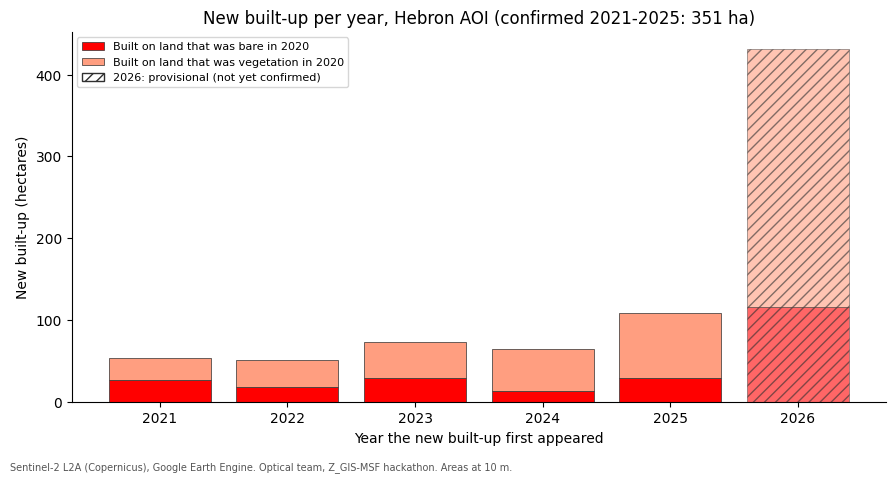

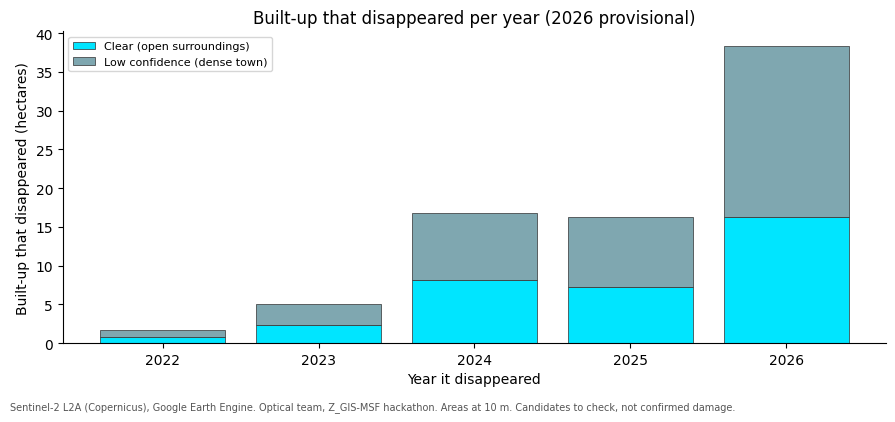

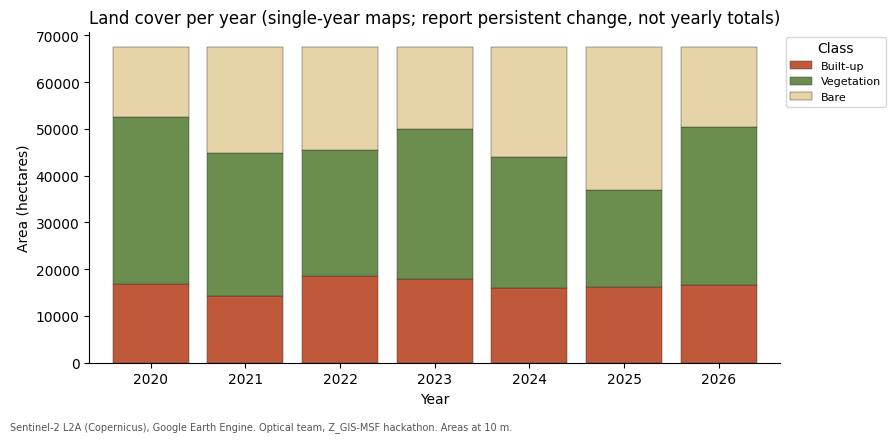

In [ ]:
# WHAT THIS CELL DOES
# Charts with titles, axis labels, legends and source line: new built-up per year (10 m official numbers),
# built-up that disappeared, and land cover per year.

# 1) New built-up per year
fig, ax = plt.subplots(figsize=(9, 4.8))
b1 = ax.bar(stats.index, stats.from_bare_ha, color=C_RED, edgecolor=C_CHARCOAL, lw=0.5, label='Built on land that was bare in 2020')
b2 = ax.bar(stats.index, stats.from_vegetation_ha, bottom=stats.from_bare_ha, color='#ff9e80', edgecolor=C_CHARCOAL, lw=0.5,
            label='Built on land that was vegetation in 2020')
for bars in (b1, b2): bars[-1].set_hatch('///'); bars[-1].set_alpha(0.6)          # 2026 = provisional
h, _ = ax.get_legend_handles_labels()
h.append(mpatches.Patch(facecolor='white', edgecolor=C_CHARCOAL, hatch='///', label=f'{Y1}: provisional (not yet confirmed)'))
ax.legend(handles=h, frameon=True, fontsize=8, loc='upper left')
ax.set_ylabel('New built-up (hectares)'); ax.set_xlabel('Year the new built-up first appeared'); ax.set_xticks(stats.index)
ax.set_title(f"New built-up per year, Hebron AOI (confirmed {CONFIRMED_YEARS[0]}-{CONFIRMED_YEARS[-1]}: {conf.new_built_ha.sum():,.0f} ha)")
ax.spines[['top', 'right']].set_visible(False)
caption(fig, SOURCE_NOTE + ' Areas at 10 m.'); plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(f'{OUT}/{nm("Chart_NewBuiltupPerYear")}.png', dpi=200); plt.show()

# 2) Built-up that disappeared per year
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(lost_stats.index, lost_stats.clear_ha, color=C_LOST, edgecolor=C_CHARCOAL, lw=0.5, label='Clear (open surroundings)')
ax.bar(lost_stats.index, lost_stats.low_confidence_ha, bottom=lost_stats.clear_ha, color=C_LOST_LOW, edgecolor=C_CHARCOAL, lw=0.5,
       label='Low confidence (dense town)')
ax.set_ylabel('Built-up that disappeared (hectares)'); ax.set_xlabel('Year it disappeared'); ax.set_xticks(lost_stats.index)
ax.set_title(f'Built-up that disappeared per year ({Y1} provisional)'); ax.legend(frameon=True, fontsize=8, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
caption(fig, SOURCE_NOTE + ' Areas at 10 m. Candidates to check, not confirmed damage.'); plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(f'{OUT}/{nm("Chart_BuiltupDisappeared")}.png', dpi=200); plt.show()

# 3) Land cover per year
fig, ax = plt.subplots(figsize=(9, 4.4))
lc_areas.plot(kind='bar', stacked=True, color=LC_PALETTE, ax=ax, width=0.8, edgecolor=C_CHARCOAL, lw=0.3)
ax.set_ylabel('Area (hectares)'); ax.set_xlabel('Year')
ax.set_title('Land cover per year (single-year maps; report persistent change, not yearly totals)')
ax.legend(title='Class', frameon=True, fontsize=8, bbox_to_anchor=(1, 1)); ax.tick_params(axis='x', labelrotation=0)
ax.spines[['top', 'right']].set_visible(False)
caption(fig, SOURCE_NOTE + ' Areas at 10 m.'); plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(f'{OUT}/{nm("Chart_LandCoverPerYear")}.png', dpi=200); plt.show()

## 1.9 Time-series GIFs and static maps
Every GIF frame carries a **title + image date box** and a **legend box**. Static maps carry title, legend, scale bar, north arrow and source line. GIFs: whole AOI, hotspots, and places with confirmed new built-up (places skipped in `budget_mode`). Pictures are requested in parallel.

In [ ]:
# WHAT THIS CELL DOES
# Makes labelled GIFs (downloaded to your PC) and the labelled overview and zoom maps (PNG).

GIF_LEGEND = [('New built-up this year', C_RED), ('New built-up in earlier years', C_DARKRED), (f'{Y1}: provisional', C_PROV)]

def frame(y, site_geom=None):
    layers = [IMG[(y, 'summer')].visualize(**RGB).multiply(0.8).toUint8(), solid(year_new.lt(y), C_DARKRED), solid(year_new.eq(y), C_RED)]
    if y == Y1: layers.append(solid(provisional, C_PROV))
    layers.append(outline(AOI, '#ffffff', 1))
    if site_geom is not None: layers.append(outline(site_geom, '#ffff00', 2))
    return ee.ImageCollection(layers).mosaic()

def make_gif(job):
    ext, name, title, site_geom, dim = job
    path = f'{OUT}/{name}.gif'
    def go():
        url = ee.ImageCollection([frame(y, site_geom) for y in YEARS]).getVideoThumbURL(
            {'region': rect(ext), 'dimensions': dim, 'framesPerSecond': 1, 'crs': 'EPSG:3857'})
        r = requests.get(url, timeout=600); r.raise_for_status(); open(path, 'wb').write(r.content)
    with_retry(go)
    annotate_gif(path, [f'{y} ({SUMMER_DATE[y]})' for y in YEARS], GIF_LEGEND, title)
    return path

gif_jobs = [(AOI_EXT, nm('GIF_NewBuiltup_AOI'), 'New built-up, Hebron AOI', None, CONFIG['gif_dim_aoi'])]
gif_jobs += [(bbox(h['lon'], h['lat'], CONFIG['zoom_half_m']), nm(f"GIF_NewBuiltup_{safe(h['name'])}"), h['name'], None, CONFIG['gif_dim_zoom']) for h in HOTSPOTS]
if not CONFIG['budget_mode'] and len(place_results):
    det = place_results.set_index('name').detected
    gif_jobs += [(bbox(p['lon'], p['lat'], CONFIG['zoom_half_m']), nm(f"GIF_NewBuiltup_{safe(p['name'])}"), p['name'], p['geom'], CONFIG['gif_dim_zoom'])
                 for p in PLACES if det.get(p['name'], False)]
with ThreadPoolExecutor(CONFIG['threads']) as ex: GIFS = list(ex.map(make_gif, gif_jobs))
print(len(GIFS), 'GIFs saved'); geemap.show_image(GIFS[0])
if CONFIG['auto_download_gifs']:
    for g in GIFS: files.download(g)

# Overview + zoom panels (all pictures fetched together)
map_leg = [(f'Built-up {Y0}', C_CHARCOAL), ('New built-up 2021-2025 (confirmed)', C_RED), (f'New built-up {Y1} (provisional)', C_PROV),
           ('Built-up disappeared', C_LOST), ('AOI', '#ffff00', 'outline')]
ov_vis = ee.ImageCollection([IMG[(Y1, 'summer')].visualize(**RGB), baseline.selfMask().visualize(palette=[C_CHARCOAL], opacity=0.45),
                             solid(built_lost, C_LOST), solid(provisional, C_PROV), solid(new_built, C_RED), outline(AOI, '#ffff00')]).mosaic()
zooms = [(f"{h['name']}: {h['area_ha']:.1f} ha bare to built (first {h['year']})", h['lon'], h['lat']) for h in HOTSPOTS]
if len(place_results): zooms += [(r['name'], r['lon'], r['lat']) for _, r in place_results[place_results.detected].iterrows()]
chg_vis = ee.ImageCollection([IMG[(Y1, 'summer')].visualize(**RGB), solid(built_lost, C_LOST), solid(provisional, C_PROV), solid(new_built, C_RED)]).mosaic()
jobs = [(ov_vis, AOI_EXT, 1400)]
for _, lon, lat in zooms:
    e = bbox(lon, lat, CONFIG['zoom_half_m'])
    jobs += [(IMG[(Y0, 'summer')].visualize(**RGB), e, CONFIG['thumb_dim']), (IMG[(Y1, 'summer')].visualize(**RGB), e, CONFIG['thumb_dim']), (chg_vis, e, CONFIG['thumb_dim'])]
pics = fetch(jobs)

fig, ax = plt.subplots(figsize=(10, 10.5))
draw(ax, pics[0], AOI_EXT); ax.set_title(f'Built-up change {Y0}-{Y1}, Hebron AOI (Sentinel-2, 10 m)', fontsize=13)
scalebar(ax, AOI_EXT, 5000); north_arrow(ax); legend(ax, map_leg, loc='lower right', fontsize=9, title='Legend')
caption(fig, SOURCE_NOTE + f' Background: summer {Y1} ({SUMMER_DATE[Y1]}).'); plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.savefig(f'{OUT}/{nm("Map_BuiltupChange_Overview")}.png', dpi=250); plt.show()

for k, (name, lon, lat) in enumerate(zooms):
    e = bbox(lon, lat, CONFIG['zoom_half_m']); p0, p1, p2 = pics[1 + 3 * k: 4 + 3 * k]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.6))
    draw(axes[0], p0, e, f'Before: summer {Y0} ({SUMMER_DATE[Y0]})'); draw(axes[1], p1, e, f'After: summer {Y1} ({SUMMER_DATE[Y1]})')
    draw(axes[2], p2, e, f'{Y1} with detected change'); scalebar(axes[0], e, 200); north_arrow(axes[0])
    legend(axes[2], map_leg[1:4], loc='lower right', fontsize=7, title='Legend')
    fig.suptitle(f'{name}   ({lat:.4f}, {lon:.4f})', fontsize=12); caption(fig, SOURCE_NOTE)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]); plt.savefig(f"{OUT}/Map_Zoom_{safe(name.split(':')[0])}.png", dpi=220); plt.show()

15 GIFs saved


Output()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (23 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

HTTPError: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/geohum-514922/thumbnails/b2cb99c2d2f4cadf80462993fe8ed861-05ec1fca2b953e473868da54a972fe60:getPixels

## 1.10 Validation points
Random points in four groups: *new built-up*, *stable built-up*, *stable not built*, and **where we and Dynamic World disagree (2026)**. Made locally, saved in the GeoPackage. Label `reference_class` on dated high-resolution imagery (Esri Wayback, Google Earth) to get a real accuracy and to see who is right where we differ.

In [ ]:
# WHAT THIS CELL DOES
# Draws random validation points locally from the downloaded stack.

rng = np.random.default_rng(7)
groups = {'new built-up (this analysis)': L['new_year'] > 0,
          'stable built-up': (L['built_2020'] == 1) & (L['lost_year'] == 0),
          'stable not built': INSIDE & (L['built_2020'] == 0) & (L['new_year'] == 0) & (L['new_2026_provisional'] == 0) & (L['landcover_2026'] != 1),
          'disagree with Dynamic World 2026': INSIDE & ((L['landcover_2026'] == 1) != (L['dw_built_2026'] == 1))}
pts = []
for g, m in groups.items():
    rr, cc = np.nonzero(m)
    if len(rr) == 0: continue
    pick = rng.choice(len(rr), min(CONFIG['n_validation'], len(rr)), replace=False)
    xs, ys = rasterio.transform.xy(TR, rr[pick], cc[pick])
    pts.append(gpd.GeoDataFrame({'group': g, 'map_built_2026': (L['landcover_2026'][rr[pick], cc[pick]] == 1),
                                 'dw_built_2026': (L['dw_built_2026'][rr[pick], cc[pick]] == 1)},
                                geometry=gpd.points_from_xy(xs, ys), crs=CRS))
val_gdf = pd.concat(pts, ignore_index=True).to_crs(4326); val_gdf['reference_class'] = ''
val_gdf['lon'], val_gdf['lat'] = val_gdf.geometry.x.round(6), val_gdf.geometry.y.round(6)
print(val_gdf.group.value_counts())

group
new built-up (this analysis)        100
stable built-up                     100
stable not built                    100
disagree with Dynamic World 2026    100
Name: count, dtype: int64


## 1.11 Optional: independence test (own polygons only)
Retrains the model using **only your drawn correction polygons** (no product labels) and compares the confirmed new built-up. Needs at least 2 polygons for each class (`built`, `vegetation`, `bare`). Similar results = the product labels were not driving the result. Skipped in `budget_mode`.

In [ ]:
# WHAT THIS CELL DOES
# (optional) Trains a second model on your own polygons only and compares its new built-up with ours.

counts = pd.Series([c for _, c in EXTRA]).value_counts()
if CONFIG['budget_mode']:
    print('Skipped (budget_mode).')
elif any(counts.get(c, 0) < 2 for c in (0, 1, 2)):
    print('Draw at least 2 polygons for each class in 1.2 (built, vegetation, bare), then run this cell.')
else:
    fc = ee.FeatureCollection([ee.Feature(g, {'lc': c}) for g, c in EXTRA])
    own = ee.FeatureCollection([FEATS[y].sampleRegions(collection=fc, properties=['lc'], scale=SCALE, tileScale=4) for y in (Y0, Y1)]).flatten()
    own, _ = fetch_fc(own.randomColumn('r', 1).sort('r').limit(4000), keep=set(FEATURE_NAMES.getInfo()) | {'lc'})
    rf_own = ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42).train(own, 'lc', FEATURE_NAMES)
    R_own = build_change({y: FEATS[y].classify(rf_own.setOutputMode('MULTIPROBABILITY')).arrayGet([0]) for y in YEARS},
                         {y: FEATS[y].classify(rf_own) for y in YEARS})
    s = (HA.updateMask(new_built).rename('ours').addBands(HA.updateMask(R_own['new_built']).rename('own'))
           .addBands(HA.updateMask(new_built.And(R_own['new_built'])).rename('both'))
           .reduceRegion(ee.Reducer.sum(), AOI, 30, maxPixels=1e10, tileScale=4).getInfo())
    indep = pd.Series({'Our confirmed new built-up (ha)': s['ours'], 'Own-polygons-only model (ha)': s['own'],
                       'Overlap (ha)': s['both'], 'Share of ours also found by own-polygons model (%)': s['both'] / max(s['ours'], 1e-9) * 100}).round(1)
    indep.to_csv(f'{OUT}/{nm("IndependenceTest")}.csv'); display(indep.to_frame('value'))

# PART 2 – Damage from reports

Three checks per incident:
1. **Site vs surroundings** – site minus a ring around it, every image ±3 months; passes if the site gets clearly barer (bulldozed, rubble) after the date.
2. **Local change map** – 3 weeks before vs after, pixel by pixel, area-wide shift removed; passes with a compact patch of ≥ 5 changed pixels in the site.
3. **Single-day strip** – every day around the date, no cloud mask: real change appears and **stays**; a shadow appears on one day only.

**Verdict:** *candidate* (1 and 2) · *possible* (one of them) · *not visible at 10 m* (neither: too small to see, not "did not happen") · *too few images*.

**Adding incidents:** by coordinates, by name, by drawing, or **upload a KMZ / KML / GeoJSON** with `add_incidents_file()`. Points or polygons (polygons are best for a village or cleared area; lines become a 20 m strip, good for roads). **Date**: a `date` field, a KML timestamp, or the date in the name or description, e.g. `Al-Tabban | 2026-09-02`. Placemarks without a date are listed; give them dates with `add_pending({...})`.

In [ ]:
# WHAT THIS CELL DOES
# ✏️ Builds the incident list from YOUR UPLOADED FILES plus a few pre-loaded reports with known coordinates.
#    Run it -> a file picker opens -> choose one or more KMZ / KML / GeoJSON / GeoPackage files.
#    - One placemark per incident. Polygons are used as drawn (best for a village or cleared area);
#      points get a circle of BUFFER_M metres; lines become a 20 m strip (roads).
#    - Date per placemark: a 'date' field, the KML timestamp, or in the name/description, e.g. "Al-Tabban | 2026-09-02".
#      No date in the file? Add it to DATES below (name as shown in the list) and run again.
#    - Incidents outside the AOI are removed and reported. Running the cell again starts the list fresh.

UPLOAD   = True          # False = skip the file picker and use only the pre-loaded incidents
BUFFER_M = 150           # circle radius (m) for incidents given as points
DATES    = {}            # ✏️ e.g. {"Khallet ad-Dabe": "2025-05-05", "Al-Tabban": "2026-09-02"}

INCIDENTS, NO_DATE = [], []
inside_aoi = aoi_shape.buffer(0.01)

def add_incident(name, date, lat=None, lon=None, source='', buffer_m=BUFFER_M, geom=None):
    '''Adds one incident from coordinates or from a shape read from a file. Skips anything outside 2020-2026 or the AOI.'''
    if not (Y0 <= pd.Timestamp(date).year <= Y1):
        print(f'  skipped {name}: date {date} outside {Y0}-{Y1}'); return
    if geom is not None:
        c = geom.centroid; lat, lon = c.y, c.x; eg = to_ee_geom(geom, buffer_m)
    else:
        eg = ee.Geometry.Point([lon, lat]).buffer(buffer_m)
    if not inside_aoi.contains(shapely.geometry.Point(lon, lat)):
        print(f'  skipped {name}: outside the AOI ({lat:.4f}, {lon:.4f})'); return
    INCIDENTS.append(dict(name=name, date=date, lat=lat, lon=lon, source=source, geom=eg))
    print(f'  added {name} ({date}): {lat:.5f}, {lon:.5f}')

# ---- pre-loaded reports with known coordinates ----
add_incident('Farsh al-Hawa, demolitions', '2026-10-23', lat=31.55707, lon=35.06644, buffer_m=250,
             source='BBC 24 Oct 2026; Roya News; location OpenStreetMap')
add_incident('Ein Deir Baha, demolition of gunmen homes', '2026-10-30', lat=31.5381, lon=35.0811, buffer_m=150,
             source='Turkiye Today / AFP 31 Oct 2026; open-source geolocation')
add_incident('Deirat, demolitions May-July 2025', '2025-05-04', lat=31.4446, lon=35.1586, buffer_m=300, source='Vashti Media')
add_incident('Mount Tarusa, bulldozing for new settlement', '2026-06-17', lat=31.52526, lon=34.98372, buffer_m=400,
             source='WAFA 17 Jun 2026; Arab News; location OpenStreetMap')

# ---- your files ----
if UPLOAD:
    print('\nChoose your incident file(s):')
    up = files.upload()
    for p in up.keys():
        for _, r in read_features(p).iterrows():
            name = clean_name(r.get('Name', r.get('name', os.path.splitext(p)[0])))
            date = find_date(r) or DATES.get(name)
            if date: add_incident(name, date, source=f'file {p}', geom=r.geometry)
            else: NO_DATE.append(name)
    if NO_DATE:
        print('\nNo date found for these placemarks (add them to DATES above and run again):')
        for n in NO_DATE: print(f'  "{n}": "YYYY-MM-DD",')

# ---- check: table + labelled map ----
display(pd.DataFrame([{k: v for k, v in i.items() if k != 'geom'} for i in INCIDENTS]))
mi = geemap.Map(); mi.add_basemap('HYBRID'); mi.addLayer(aoi_outline, {'palette': ['#ffff00']}, 'AOI')
for i in INCIDENTS:
    mi.addLayer(outline(i['geom'], '#ff0000', 2), {}, i['name']); map_label(mi, i['lat'], i['lon'], f"{i['name']} ({i['date']})")
mi.add_legend(title='Incidents', legend_dict={'Reported incident site': '#ff0000', 'AOI': '#ffff00'}, position='bottomright')
mi.centerObject(AOI, 11); mi

  added Farsh al-Hawa, demolitions (2026-10-23): 31.55707, 35.06644
  added Ein Deir Baha, demolition of gunmen homes (2026-10-30): 31.53810, 35.08110
  added Deirat, demolitions May-July 2025 (2025-05-04): 31.44460, 35.15860
  added Mount Tarusa, bulldozing for new settlement (2026-06-17): 31.52526, 34.98372

Choose your incident file(s):


Saving BeitUmmar.kmz to BeitUmmar.kmz
Saving Dura_Qilqis_yatta.kmz to Dura_Qilqis_yatta.kmz
Saving MasaferYatta.kmz to MasaferYatta.kmz

No date found for these placemarks (add them to DATES above and run again):
  "BeitUmmar": "YYYY-MM-DD",
  "Dura_Qilqis_yatta": "YYYY-MM-DD",
  "Masafer Yatta": "YYYY-MM-DD",


,name,date,lat,lon,source
0,"Farsh al-Hawa, demolitions",2026-10-23,31.55707,35.06644,BBC 24 Oct 2026; Roya News; location OpenStree...
1,"Ein Deir Baha, demolition of gunmen homes",2026-10-30,31.53810,35.08110,Turkiye Today / AFP 31 Oct 2026; open-source g...
2,"Deirat, demolitions May-July 2025",2025-05-04,31.44460,35.15860,Vashti Media
3,"Mount Tarusa, bulldozing for new settlement",2026-06-17,31.52526,34.98372,WAFA 17 Jun 2026; Arab News; location OpenStre...


Map(center=[31.486486120813037, 35.0842538691304], controls=(WidgetControl(options=['position', 'transparent_b…

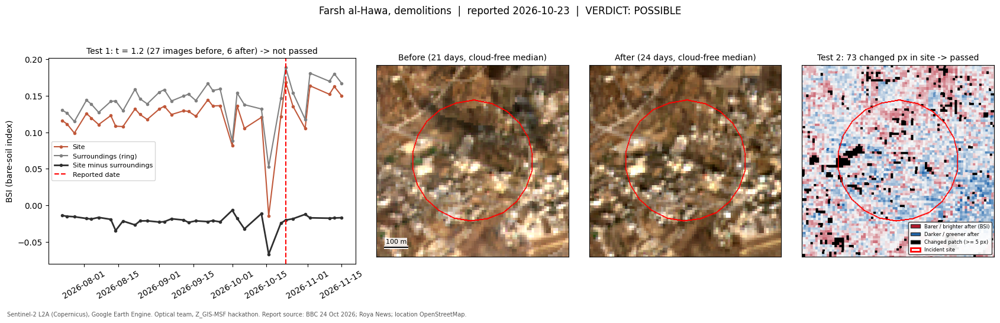

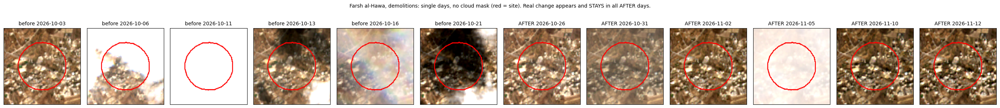

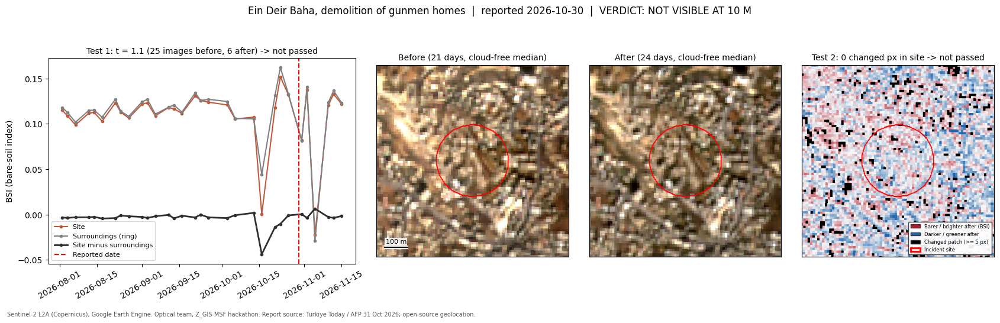

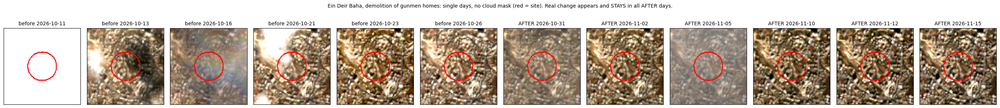

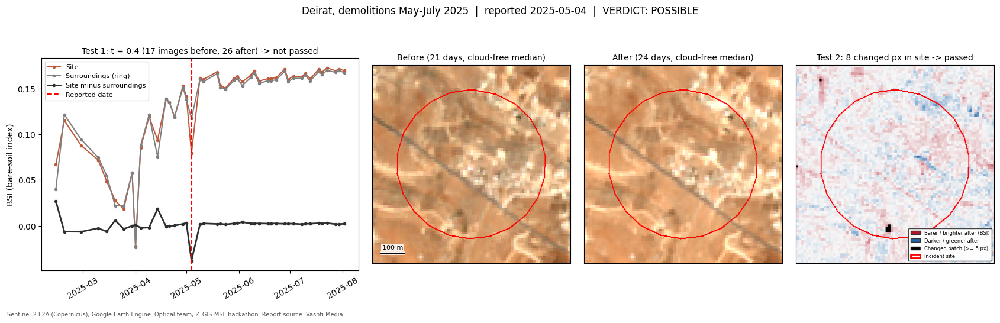

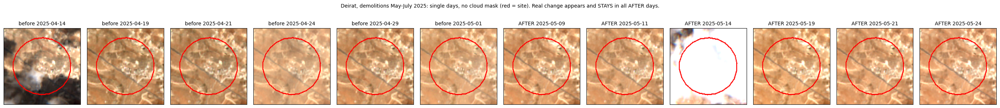

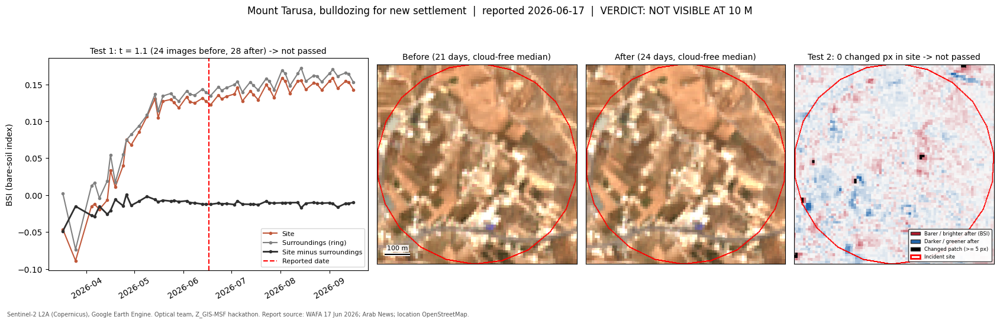

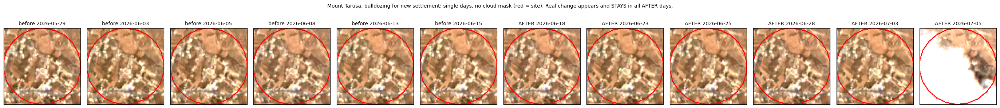

verdict
possible               2
not visible at 10 m    2


,name,date,source,lat,lon,images_before,images_after,test1_t,test1_passed,test2_changed_pixels,test2_passed,area_shift_removed,on_part1_loss_layer,verdict
0,"Farsh al-Hawa, demolitions",2026-10-23,BBC 24 Oct 2026; Roya News; location OpenStree...,31.55707,35.06644,27,6,1.24,False,73,True,0.0180,True,possible
1,"Ein Deir Baha, demolition of gunmen homes",2026-10-30,Turkiye Today / AFP 31 Oct 2026; open-source g...,31.53810,35.08110,25,6,1.08,False,0,False,-0.0111,True,not visible at 10 m
2,"Deirat, demolitions May-July 2025",2025-05-04,Vashti Media,31.44460,35.15860,17,26,0.43,False,8,True,0.0213,False,possible
3,"Mount Tarusa, bulldozing for new settlement",2026-06-17,WAFA 17 Jun 2026; Arab News; location OpenStre...,31.52526,34.98372,24,28,1.07,False,0,False,0.0041,True,not visible at 10 m


In [ ]:
# WHAT THIS CELL DOES
# Runs the three checks for every incident and gives a verdict. Reads only a 400 m box per site;
# pictures are fetched in parallel. One labelled figure per incident (+ single-day strip) and a results table.

IDX = CONFIG['damage_index']
CHANGE_LEG = [(f'Barer / brighter after ({IDX})', '#b2182b'), ('Darker / greener after', '#2166ac'),
              (f"Changed patch (>= {CONFIG['min_pixels']} px)", '#000000'), ('Incident site', '#ff0000', 'outline')]

def masked_box(region, start, end):
    return (S2.filterBounds(region).filterDate(start, end).linkCollection(CSP, ['cs_cdf'])
              .map(lambda i: add_indices(i.updateMask(i.select('cs_cdf').gte(CONFIG['cloud_thresh'])).select(S2_BANDS).divide(10000))
                   .copyProperties(i, ['system:time_start'])))

def evaluate(inc):
    d = pd.Timestamp(inc['date']); geom = inc['geom']; ring = ring_of(geom)
    ext = bbox(inc['lon'], inc['lat'], 400); region = rect(ext)
    # Test 1: site minus surroundings, every image
    m = pd.DateOffset(months=CONFIG['incident_window_months'])
    start, end = max(d - m, pd.Timestamp(f'{Y0}-01-01')), min(d + m, pd.Timestamp.today())
    def f(img):
        img = ee.Image(img).select(IDX)
        return ee.Feature(None, {'site': img.reduceRegion(ee.Reducer.mean(), geom, SCALE).get(IDX),
                                 'ring': img.reduceRegion(ee.Reducer.mean(), ring, SCALE).get(IDX), 'date': img.date().format('YYYY-MM-dd')})
    rows = [x['properties'] for x in masked_box(ring.bounds(), start.strftime('%Y-%m-%d'), end.strftime('%Y-%m-%d')).map(f).getInfo()['features']]
    ts = pd.DataFrame(rows).dropna()
    if len(ts):
        ts['date'] = pd.to_datetime(ts['date']); ts = ts.groupby('date').mean().sort_index(); ts['diff'] = ts.site - ts.ring
        pre, post = ts[ts.index < d]['diff'], ts[ts.index > d]['diff']
    else:
        pre = post = pd.Series(dtype=float)
    t = tstat(pre, post)
    # Test 2: local change map
    b_, a_ = CONFIG['change_days']
    pre_img  = masked_box(region, (d - pd.Timedelta(days=b_)).strftime('%Y-%m-%d'), d.strftime('%Y-%m-%d')).median().clip(region)
    post_img = masked_box(region, (d + pd.Timedelta(days=1)).strftime('%Y-%m-%d'), (d + pd.Timedelta(days=a_)).strftime('%Y-%m-%d')).median().clip(region)
    diff = post_img.select(IDX).subtract(pre_img.select(IDX))
    shift = diff.reduceRegion(ee.Reducer.median(), region.difference(geom, 1), 30, maxPixels=1e8).getInfo().get(IDX) or 0
    local = diff.subtract(shift)
    changed = keep_patches(local.gt(CONFIG['change_thr'][IDX]).selfMask(), CONFIG['min_pixels'])
    n_px = changed.reduceRegion(ee.Reducer.count(), geom, SCALE).getInfo().get(IDX) or 0
    lost = HA.updateMask(built_lost).reduceRegion(ee.Reducer.sum(), geom.buffer(20), SCALE).getInfo().get('area') or 0
    test1 = bool(t >= CONFIG['t_threshold']) if not np.isnan(t) else False
    test2 = n_px >= CONFIG['min_pixels']
    verdict = ('too few images' if (len(pre) < 3 or len(post) < 3) and not test2 else
               'candidate' if test1 and test2 else 'possible' if test1 or test2 else 'not visible at 10 m')
    lim = CONFIG['change_thr'][IDX] * 1.5
    pics = fetch([(ee.ImageCollection([pre_img.visualize(**RGB), outline(geom, '#ff0000')]).mosaic(), ext, 400),
                  (ee.ImageCollection([post_img.visualize(**RGB), outline(geom, '#ff0000')]).mosaic(), ext, 400),
                  (ee.ImageCollection([local.visualize(min=-lim, max=lim, palette=['#2166ac', '#f7f7f7', '#b2182b']),
                                       solid(changed, '#000000'), outline(geom, '#ff0000')]).mosaic(), ext, 400)])
    fig = plt.figure(figsize=(17, 5.4)); gs = fig.add_gridspec(1, 4, width_ratios=[1.6, 1, 1, 1])
    ax = fig.add_subplot(gs[0, 0])
    if len(ts):
        ax.plot(ts.index, ts.site, 'o-', ms=3, color=C_TERRACOTTA, label='Site'); ax.plot(ts.index, ts.ring, 'o-', ms=3, color='grey', label='Surroundings (ring)')
        ax.plot(ts.index, ts['diff'], 'o-', ms=3, color=C_CHARCOAL, lw=2, label='Site minus surroundings')
    ax.axvline(d, color='red', ls='--', label='Reported date'); ax.legend(frameon=True, fontsize=8); ax.set_ylabel(f'{IDX} (bare-soil index)' if IDX == 'BSI' else IDX)
    ax.set_title(f"Test 1: t = {t:.1f} ({len(pre)} images before, {len(post)} after) -> {'passed' if test1 else 'not passed'}", fontsize=10)
    ax.tick_params(axis='x', labelrotation=30)
    draw(fig.add_subplot(gs[0, 1]), pics[0], ext, f'Before ({b_} days, cloud-free median)')
    draw(fig.add_subplot(gs[0, 2]), pics[1], ext, f'After ({a_} days, cloud-free median)')
    ax4 = fig.add_subplot(gs[0, 3]); draw(ax4, pics[2], ext, f"Test 2: {n_px} changed px in site -> {'passed' if test2 else 'not passed'}")
    legend(ax4, CHANGE_LEG, loc='lower right', fontsize=6); scalebar(fig.axes[1], ext, 100)
    fig.suptitle(f"{inc['name']}  |  reported {inc['date']}  |  VERDICT: {verdict.upper()}", fontsize=12)
    caption(fig, SOURCE_NOTE + f" Report source: {inc['source']}."); plt.tight_layout(rect=[0, 0.03, 1, 0.94])
    plt.savefig(f"{OUT}/Incident_{safe(inc['name'])}.png", dpi=170); plt.show()
    if not CONFIG['budget_mode']: day_strip(inc, ext)
    return dict(name=inc['name'], date=inc['date'], source=inc['source'], lat=round(inc['lat'], 5), lon=round(inc['lon'], 5),
                images_before=len(pre), images_after=len(post), test1_t=None if np.isnan(t) else round(t, 2), test1_passed=test1,
                test2_changed_pixels=int(n_px), test2_passed=test2, area_shift_removed=round(shift, 4), on_part1_loss_layer=lost > 0, verdict=verdict)

def day_strip(inc, ext, max_days=6):
    d = pd.Timestamp(inc['date']); b_, a_ = CONFIG['change_days']
    col = S2.filterBounds(rect(ext)).filterDate((d - pd.Timedelta(days=b_)).strftime('%Y-%m-%d'), (d + pd.Timedelta(days=a_)).strftime('%Y-%m-%d'))
    days = sorted(set(pd.to_datetime(col.aggregate_array('system:time_start').getInfo(), unit='ms').strftime('%Y-%m-%d')))
    sel = [x for x in days if pd.Timestamp(x) < d][-max_days:] + [x for x in days if pd.Timestamp(x) > d][:max_days]
    if not sel: print('  no single days to show'); return
    pics = fetch([(ee.ImageCollection([col.filterDate(x, (pd.Timestamp(x) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')).mosaic().divide(10000).visualize(**RGB),
                                       outline(inc['geom'], '#ff0000')]).mosaic(), ext, 170) for x in sel])
    fig, axes = plt.subplots(1, len(sel), figsize=(2.3 * len(sel), 3.0))
    for ax, x, pic in zip(np.atleast_1d(axes), sel, pics): draw(ax, pic, ext, ('AFTER ' if pd.Timestamp(x) > d else 'before ') + x)
    fig.suptitle(f"{inc['name']}: single days, no cloud mask (red = site). Real change appears and STAYS in all AFTER days.", fontsize=10)
    plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.savefig(f"{OUT}/Incident_{safe(inc['name'])}_days.png", dpi=150); plt.show()

if not INCIDENTS:
    incident_results = pd.DataFrame(); print('No incidents yet: add them in the cells above.')
else:
    incident_results = pd.DataFrame([evaluate(i) for i in INCIDENTS])
    incident_results.to_csv(f'{OUT}/{nm("ReportedIncidentsCheck")}.csv', index=False)
    print(incident_results.verdict.value_counts().to_string()); display(incident_results)

# PART 3 – Focus areas and downloads

## 3.1 Statistics and a map per MSF focus area
Upload the focus-area files together: **`BeitUmmar.kmz`, `Dura_Qilqis_yatta.kmz`, `MasaferYatta.kmz`** (any KMZ / KML / GeoJSON works). Each area is named after its file. Statistics come from the downloaded stack (no Earth Engine work).

Saving BeitUmmar.kmz to BeitUmmar (1).kmz
Saving Dura_Qilqis_yatta.kmz to Dura_Qilqis_yatta (1).kmz
Saving MasaferYatta.kmz to MasaferYatta (1).kmz


,area_name,area_km2,built_2020_ha,new_confirmed_ha,bare_to_built_ha,new_2026_provisional_ha,built_lost_ha,new_2021_ha,new_2022_ha,new_2023_ha,new_2024_ha,new_2025_ha,new_confirmed_pct_of_2020
0,BeitUmmar (1),24.07,709.01,35.83,5.13,33.02,4.33,2.80,5.28,9.25,7.36,11.14,5.1
1,Dura_Qilqis_yatta (1),123.59,2999.39,85.81,34.51,109.14,20.82,15.77,11.98,19.88,14.33,23.85,2.9
2,MasaferYatta (1),14.74,12.30,0.00,0.00,0.16,0.10,0.00,0.00,0.00,0.00,0.00,0.0


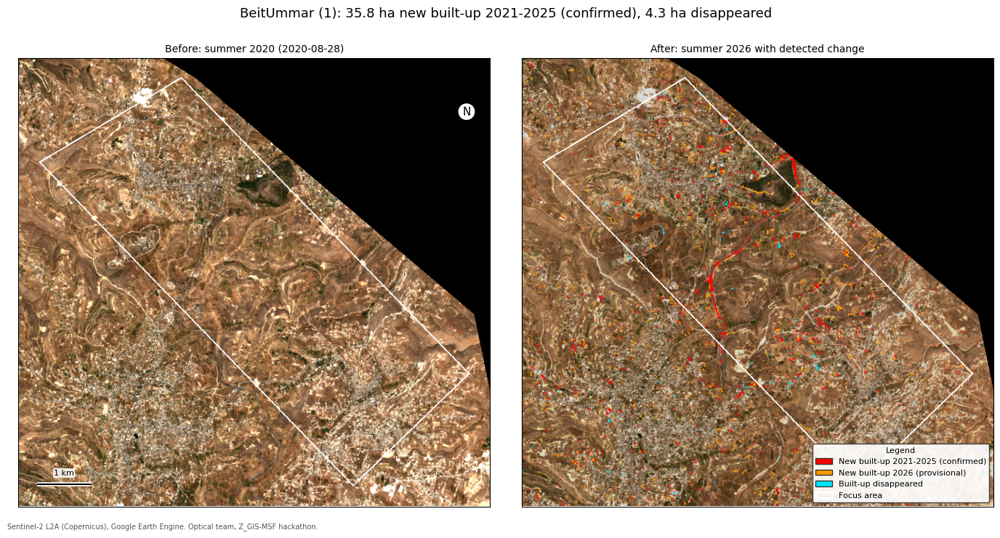

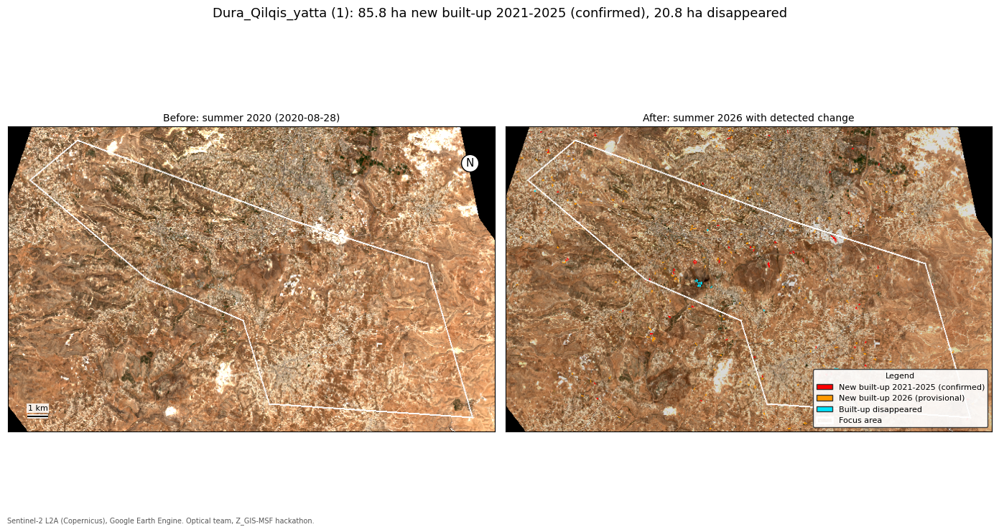

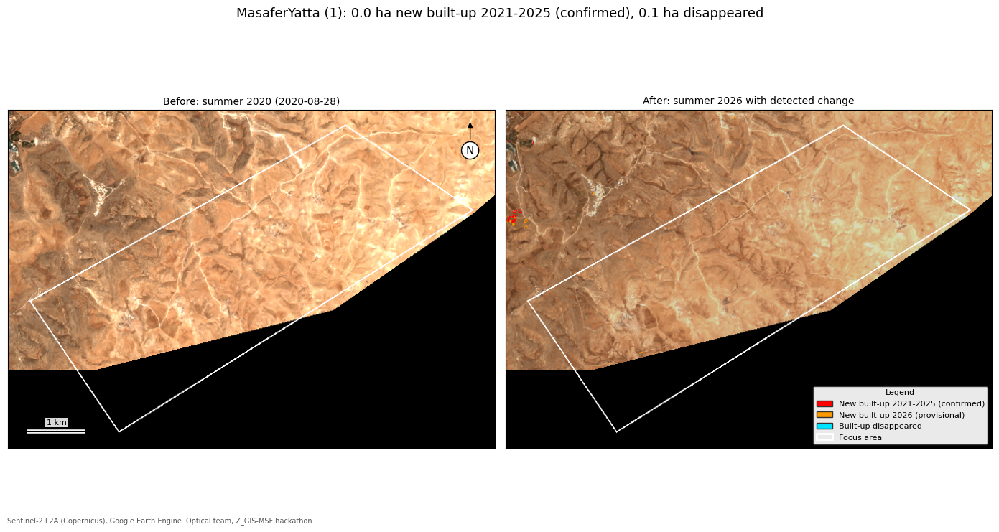

In [ ]:
# WHAT THIS CELL DOES
# Uploads focus-area files, computes statistics locally, and draws a labelled before/after map per area.

up = files.upload()
focus = pd.concat([read_vector(p).assign(area_name=os.path.splitext(os.path.basename(p))[0])[['area_name', 'geometry']] for p in up.keys()])
focus = gpd.GeoDataFrame(focus, geometry='geometry', crs=4326).dissolve('area_name').reset_index()
focus_utm = focus.to_crs(CRS)

rows = []
for (_, r), geom in zip(focus.iterrows(), focus_utm.geometry):
    m = rasterio.features.geometry_mask([geom], out_shape=SHAPE, transform=TR, invert=True) & INSIDE
    rows.append({'area_name': r.area_name, 'area_km2': m.sum() * PX_HA / 100,
                 'built_2020_ha': (m & (L['built_2020'] == 1)).sum() * PX_HA,
                 'new_confirmed_ha': (m & (L['new_year'] > 0)).sum() * PX_HA,
                 'bare_to_built_ha': (m & (L['bare_to_built'] == 1)).sum() * PX_HA,
                 'new_2026_provisional_ha': (m & (L['new_2026_provisional'] == 1)).sum() * PX_HA,
                 'built_lost_ha': (m & (L['lost_year'] > 0)).sum() * PX_HA,
                 **{f'new_{y}_ha': (m & (L['new_year'] == y - 2000)).sum() * PX_HA for y in CONFIRMED_YEARS}})
focus_stats = pd.DataFrame(rows).round(2)
focus_stats['new_confirmed_pct_of_2020'] = (focus_stats.new_confirmed_ha / focus_stats.built_2020_ha.replace(0, np.nan) * 100).round(1)
focus_stats.to_csv(f'{OUT}/{nm("FocusAreaStatistics")}.csv', index=False); display(focus_stats)

leg = [('New built-up 2021-2025 (confirmed)', C_RED), (f'New built-up {Y1} (provisional)', C_PROV), ('Built-up disappeared', C_LOST), ('Focus area', '#ffffff', 'outline')]
jobs, exts = [], []
for _, r in focus.iterrows():
    bx = r.geometry.bounds; px, py = (bx[2] - bx[0]) * 0.05, (bx[3] - bx[1]) * 0.05
    e = [bx[0] - px, bx[2] + px, bx[1] - py, bx[3] + py]; exts.append(e); g = ee.Geometry(mapping(r.geometry))
    jobs += [(ee.ImageCollection([IMG[(Y0, 'summer')].visualize(**RGB), outline(g)]).mosaic(), e, 800),
             (ee.ImageCollection([IMG[(Y1, 'summer')].visualize(**RGB).multiply(0.85).toUint8(), solid(built_lost, C_LOST), solid(provisional, C_PROV),
                                  solid(new_built, C_RED), outline(g)]).mosaic(), e, 800)]
pics = fetch(jobs)
for k, (_, r) in enumerate(focus.iterrows()):
    e = exts[k]; fig, axes = plt.subplots(1, 2, figsize=(14, 7.4))
    draw(axes[0], pics[2 * k], e, f'Before: summer {Y0} ({SUMMER_DATE[Y0]})'); draw(axes[1], pics[2 * k + 1], e, f'After: summer {Y1} with detected change')
    scalebar(axes[0], e, 1000); north_arrow(axes[0]); legend(axes[1], leg, loc='lower right', fontsize=8, title='Legend')
    s = focus_stats.iloc[k]
    fig.suptitle(f"{r.area_name}: {s.new_confirmed_ha:.1f} ha new built-up 2021-2025 (confirmed), {s.built_lost_ha:.1f} ha disappeared", fontsize=13)
    caption(fig, SOURCE_NOTE); plt.tight_layout(rect=[0, 0.03, 1, 0.95]); plt.savefig(f'{OUT}/Map_FocusArea_{safe(r.area_name)}.png', dpi=200); plt.show()

## 3.2 Download everything to your PC
Made locally from the downloaded stack (fast; no Earth Engine work except the optional true-colour images):

| Content | Format |
|---|---|
| Land cover 2020–2026, built-up 2020, year of new built-up (confirmed), new built-up 2026 (provisional), bare → built, year built-up disappeared, loss confidence, full results stack | GeoTIFF, UTM 36N, 10 m |
| Analysis extent (method + findings), new built-up patches, provisional patches, disappeared patches, hotspots, reported places, incidents, validation points, focus areas | one GeoPackage |
| All figures, GIFs and tables; `README_methods.md` | PNG, GIF, CSV, text |
| Optional (`download_images = True`): summer true-colour image per year | GeoTIFF |

In [ ]:
# WHAT THIS CELL DOES
# Writes the final rasters and GeoPackage locally, adds the README, zips everything and downloads it.

def write_band(arr, name, nodata=0, dtype='uint8'):
    with rasterio.open(f'{OUT}/{name}.tif', 'w', driver='GTiff', height=SHAPE[0], width=SHAPE[1], count=1, dtype=dtype,
                       crs=CRS, transform=TR, compress='deflate', nodata=nodata) as d: d.write(arr.astype(dtype), 1)

print('1/4 Rasters (local)...')
for y in YEARS: write_band(L[f'landcover_{y}'], nm(f'LandCover_{y}'))
write_band(L['built_2020'], nm('Builtup_2020'))
write_band(np.where(L['new_year'] > 0, L['new_year'].astype('uint16') + 2000, 0), nm('NewBuiltup_Year_Confirmed_2021_2025'), dtype='uint16')
write_band(L['new_2026_provisional'], nm('NewBuiltup_2026_Provisional'))
write_band(L['bare_to_built'], nm('BareToBuilt_2021_2025'))
write_band(np.where(L['lost_year'] > 0, L['lost_year'].astype('uint16') + 2000, 0), nm('BuiltupDisappeared_Year'), dtype='uint16')
write_band(L['lost_confidence'], nm('BuiltupDisappeared_Confidence'))
if CONFIG['download_images']:
    for y in YEARS: download_tiled(IMG[(y, 'summer')].visualize(**RGB), f"{OUT}/{nm('Image_TrueColour_' + SUMMER_DATE[y])}.tif")

print('2/4 GeoPackage (local)...')
gpkg = f'{OUT}/{nm("ChangeDetection_2020_2026")}.gpkg'
if os.path.exists(gpkg): os.remove(gpkg)
def layer(gdf, name):
    try:
        if gdf is not None and len(gdf): gpd.GeoDataFrame(gdf).to_file(gpkg, layer=name, driver='GPKG'); print('  layer', name, f'({len(gdf)})')
    except Exception as e: print('  skipped', name, str(e)[:80])
def as_points(df): return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df['lon'], df['lat']), crs=4326) if len(df) else None

extent = gpd.GeoDataFrame([{
    'title': 'Optical change detection, Hebron Governorate (v3)', 'team': 'Optical (Sentinel-2)', 'period': f'{Y0}-{Y1}',
    'sensor': 'Sentinel-2 L2A 10 m, one spring + one summer image per year, Cloud Score+ mask',
    'summer_image_dates': ', '.join(SUMMER_DATE[y] for y in YEARS),
    'method': 'Random Forest (built-up / vegetation / bare) trained on stable pixels where WorldCover and Dynamic World agree in 2020 and 2026 '
              '(built-up on mapped footprints); persistence rules; groups >= 5 pixels; incidents: site-vs-surroundings test, local change map, single days',
    'builtup_2020_ha': round(base_ha), 'new_builtup_confirmed_ha': round(conf.new_built_ha.sum()),
    'new_builtup_2026_provisional_ha': round(stats.loc[Y1, 'new_built_ha']), 'bare_to_built_confirmed_ha': round(conf.from_bare_ha.sum()),
    'builtup_disappeared_clear_ha': round(lost_stats.clear_ha.sum(), 1), 'classifier_agreement': round(train_agreement, 3),
    'share_new_also_new_in_dynamic_world_pct': float(summary.iloc[3]),
    'limits': '10 m pixels: small houses, caravans, added floors and damage without collapse not visible; 2026 provisional; '
              'change is not attributed to any actor; accuracy needs the validation points labelled',
    'created': pd.Timestamp.today().strftime('%Y-%m-%d'), 'geometry': aoi_shape}], crs=4326)
layer(extent, 'analysis_extent')
layer(new_patches, 'new_builtup_confirmed_2021_2025'); layer(prov_patches, 'new_builtup_2026_provisional'); layer(lost_patches, 'builtup_disappeared')
layer(as_points(pd.DataFrame(HOTSPOTS)), 'hotspots_bare_to_built')
if len(place_results): layer(as_points(place_results), 'reported_places_check')
if len(incident_results): layer(as_points(incident_results), 'reported_incidents_check')
layer(val_gdf, 'validation_points')
if 'focus_stats' in globals(): layer(focus.merge(focus_stats, on='area_name'), 'focus_areas_statistics')

print('3/4 README...')
readme = f'''# hebron_change_detection_v3 - outputs
Optical team, GeoHumanitarian Action hackathon (Z_GIS - MSF). Sentinel-2, {Y0}-{Y1}. Created {pd.Timestamp.today():%Y-%m-%d}.

## Key numbers (AOI {area_km2:.0f} km2)
- Built-up {Y0}: {base_ha:,.0f} ha
- New built-up {CONFIRMED_YEARS[0]}-{CONFIRMED_YEARS[-1]} (confirmed): {conf.new_built_ha.sum():,.0f} ha; on land bare in {Y0}: {conf.from_bare_ha.sum():,.0f} ha
- New built-up {Y1} (provisional): {stats.loc[Y1, 'new_built_ha']:,.0f} ha
- Built-up disappeared (clear / low confidence): {lost_stats.clear_ha.sum():,.1f} / {lost_stats.low_confidence_ha.sum():,.1f} ha
- Training pixels: {float(summary.iloc[0]):.2f} % of the AOI; share of our new built-up also new in Dynamic World: {float(summary.iloc[3]):.1f} %
- Classifier agreement with held-back samples: {train_agreement:.3f} (not a field accuracy)

## Image dates (spring {CONFIG['spring_window'][0]}..{CONFIG['spring_window'][1]}, summer {CONFIG['summer_window'][0]}..{CONFIG['summer_window'][1]}, every year)
{image_dates.to_string(index=False)}

## Raster codes (all EPSG:32636, 10 m, 0 = outside AOI / none)
- *_LandCover_YYYY.tif: 1 built-up, 2 vegetation, 3 bare
- *_Builtup_2020.tif: 1 built-up in 2020
- *_NewBuiltup_Year_Confirmed_2021_2025.tif: year it became built and stayed built
- *_NewBuiltup_2026_Provisional.tif: 1 = new in 2026, not yet confirmed
- *_BareToBuilt_2021_2025.tif: 1 = bare in 2020, confirmed built later
- *_BuiltupDisappeared_Year.tif: year; *_BuiltupDisappeared_Confidence.tif: 1 clear, 2 low (dense town)
- *_ResultsStack_2020_2026.tif bands: {', '.join(BANDS)} (land cover 1/2/3; years stored as year-2000)

## GeoPackage layers
analysis_extent, new_builtup_confirmed_2021_2025, new_builtup_2026_provisional, builtup_disappeared, hotspots_bare_to_built,
reported_places_check, reported_incidents_check, validation_points (fill reference_class), focus_areas_statistics

## Datasets
- COPERNICUS/S2_SR_HARMONIZED (all analysis); GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED (cloud mask)
- ESA/WorldCover/v200, GOOGLE/DYNAMICWORLD/V1, VIDA Google-Microsoft footprints: training samples only (stable agreeing pixels)
- JRC/GHSL: not used in v3 outputs; OpenStreetMap Nominatim: place search

## Method
- Two images per year, same weeks; clearest day, leftover cloud filled from second-clearest day
- Random Forest (100 trees) on summer bands + indices, spring indices, spring-summer greenness difference
- New built-up: not built in 2020, built from a year onwards and in all later years, probability rise >= {CONFIG['min_gain']}, >= {CONFIG['min_pixels']} px
- Built-up disappeared: built in 2020 and 2021, probability fall >= {CONFIG['loss_drop']} persisting; low confidence in dense town
- Incidents: site-vs-surroundings t-test on {IDX}; local change map (area-wide shift removed); single-day strip

## Settings
{json.dumps({str(k): v for k, v in CONFIG.items()}, indent=2, default=str)}

## Limits
- 10 m pixels: single small houses, caravans, added floors and damage without collapse are not visible.
- {Y1} is provisional. The layers show change, not who caused it. Label the validation points before quoting accuracy.
'''
open(f'{OUT}/README_methods.md', 'w').write(readme)

print('4/4 Zip and download...')
zip_path = 'hebron_change_detection_v3_outputs.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for fpath in glob.glob(f'{OUT}/**/*', recursive=True):
        if os.path.isfile(fpath): z.write(fpath, os.path.relpath(fpath, OUT))
print(f'  {zip_path}: {os.path.getsize(zip_path) / 1e6:.0f} MB'); files.download(zip_path)

1/4 Rasters (local)...
2/4 GeoPackage (local)...
  layer analysis_extent (1)
  layer new_builtup_confirmed_2021_2025 (3200)
  layer new_builtup_2026_provisional (4756)
  layer builtup_disappeared (808)
  layer hotspots_bare_to_built (4)
  layer reported_places_check (13)
  layer reported_incidents_check (4)
  layer validation_points (400)
  layer focus_areas_statistics (3)
3/4 README...
4/4 Zip and download...
  hebron_change_detection_v3_outputs.zip: 71 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>